# Phase 4 — Clustering and PCA

## Research objective
Construct participant-level features, compare K-means and DBSCAN, quantify stability/sensitivity, and use PCA as a descriptive projection. Prerequisite: the Phase 2 daily table and Phase 3 coverage definitions. The tested algorithm implementations are transferred into separate notebook code cells, and the analysis is unfolded into sequential steps.

The sample has only 35 participants. Clusters are not clinical categories; the two-person group is especially sensitive, DBSCAN depends on parameters, and PCA does not establish causality.

In [1]:
from pathlib import Path
import tempfile, json, csv, hashlib, statistics, math, sys
from IPython.display import display, HTML, SVG
def find_project_root(start=Path.cwd()):
    for candidate in (start,*start.parents):
        if (candidate/'data/processed').is_dir() and (candidate/'reports/evidence/P4').is_dir(): return candidate
    raise RuntimeError('Run this notebook from the FitInsight repository or a child directory')
ROOT=find_project_root()
def notebook_code_hash(filename):
    notebook=json.loads((ROOT/'notebooks'/'phases'/filename).read_text(encoding='utf-8'))
    source='\n\n'.join(''.join(cell.get('source',[])) for cell in notebook['cells'] if cell.get('cell_type')=='code')
    return hashlib.sha256(source.encode('utf-8')).hexdigest()
print('Repository:',ROOT)

Repository: /tmp/fitinsight-notebooks-wy4qrd8w


## Feature engineering and clustering mathematics

In [2]:
"""Small, deterministic clustering and PCA primitives for Phase 4.

This module intentionally uses only Python's standard library. Its algorithms
are tested against synthetic cases and documented as repository-local
implementations, not as bit-for-bit replacements for scikit-learn.
"""

from __future__ import annotations

import math
import random
from collections import Counter, deque
from typing import Sequence

Vector = Sequence[float]
Matrix = Sequence[Vector]

In [3]:
from __future__ import annotations
def mean(values: Sequence[float]) -> float:
    if not values:
        raise ValueError("mean requires at least one value")
    return sum(values) / len(values)

In [4]:
from __future__ import annotations
def sample_standard_deviation(values: Sequence[float]) -> float:
    """Return the sample SD (n - 1); a single observation has no SD."""
    if len(values) < 2:
        raise ValueError("sample standard deviation requires at least two values")
    center = mean(values)
    return math.sqrt(sum((value - center) ** 2 for value in values) / (len(values) - 1))

In [5]:
from __future__ import annotations
def euclidean(left: Vector, right: Vector) -> float:
    if len(left) != len(right):
        raise ValueError("vectors must have equal dimensions")
    return math.sqrt(sum((a - b) ** 2 for a, b in zip(left, right)))

In [6]:
from __future__ import annotations
def squared_euclidean(left: Vector, right: Vector) -> float:
    if len(left) != len(right):
        raise ValueError("vectors must have equal dimensions")
    return sum((a - b) ** 2 for a, b in zip(left, right))

In [7]:
from __future__ import annotations
def pearson(left: Sequence[float], right: Sequence[float]) -> float | None:
    if len(left) != len(right) or len(left) < 2:
        return None
    mean_left = mean(left)
    mean_right = mean(right)
    centered_left = [value - mean_left for value in left]
    centered_right = [value - mean_right for value in right]
    denominator = math.sqrt(
        sum(value * value for value in centered_left)
        * sum(value * value for value in centered_right)
    )
    if denominator == 0:
        return None
    return sum(a * b for a, b in zip(centered_left, centered_right)) / denominator

In [8]:
from __future__ import annotations
def standardize(
    values: Matrix, *, tolerance: float = 1e-12
) -> tuple[list[list[float]], list[dict[str, float | bool]]]:
    """Z-score columns using population SD; constant columns map to zero."""
    if not values or not values[0]:
        raise ValueError("standardization requires a non-empty rectangular matrix")
    width = len(values[0])
    if any(len(row) != width for row in values):
        raise ValueError("matrix rows must have equal dimensions")
    if any(not math.isfinite(value) for row in values for value in row):
        raise ValueError("standardization requires finite values")

    metadata: list[dict[str, float | bool]] = []
    columns: list[list[float]] = []
    for column_index in range(width):
        column = [row[column_index] for row in values]
        center = mean(column)
        population_sd = math.sqrt(sum((value - center) ** 2 for value in column) / len(column))
        constant = population_sd <= tolerance
        metadata.append({
            "mean": center,
            "population_sd": population_sd,
            "constant": constant,
        })
        columns.append(
            [0.0 for _ in column]
            if constant
            else [(value - center) / population_sd for value in column]
        )
    return [
        [columns[column_index][row_index] for column_index in range(width)]
        for row_index in range(len(values))
    ], metadata

In [9]:
from __future__ import annotations
def _nearest_labels(points: Matrix, centers: Matrix) -> list[int]:
    return [
        min(range(len(centers)), key=lambda index: squared_euclidean(point, centers[index]))
        for point in points
    ]

In [10]:
from __future__ import annotations
def _centroids(points: Matrix, labels: Sequence[int], k: int) -> list[list[float]]:
    width = len(points[0])
    counts = [0] * k
    totals = [[0.0] * width for _ in range(k)]
    for point, label in zip(points, labels):
        counts[label] += 1
        for column, value in enumerate(point):
            totals[label][column] += value
    if any(count == 0 for count in counts):
        raise ValueError("cannot calculate a centroid for an empty cluster")
    return [[value / counts[index] for value in totals[index]] for index in range(k)]

In [11]:
from __future__ import annotations
def _repair_empty_clusters(
    points: Matrix, labels: list[int], centers: list[list[float]], k: int
) -> tuple[list[int], list[list[float]]]:
    """Move a farthest point from a non-singleton donor to each empty cluster."""
    counts = Counter(labels)
    for empty in range(k):
        if counts[empty]:
            continue
        candidates = sorted(
            (
                squared_euclidean(point, centers[label]),
                -index,
                index,
                label,
            )
            for index, (point, label) in enumerate(zip(points, labels))
            if counts[label] > 1
        )
        if not candidates:
            raise ValueError("could not repair an empty K-Means cluster")
        _, _, point_index, donor = candidates[-1]
        labels[point_index] = empty
        counts[donor] -= 1
        counts[empty] += 1
        centers[empty] = list(points[point_index])
    return labels, centers

In [12]:
from __future__ import annotations
def _kmeans_once(
    points: Matrix, k: int, *, seed: int, max_iter: int, tolerance: float
) -> tuple[list[int], list[list[float]], float, int]:
    rng = random.Random(seed)
    chosen = [rng.randrange(len(points))]
    centers = [list(points[chosen[0]])]
    while len(centers) < k:
        weights = [
            min(squared_euclidean(point, center) for center in centers)
            if index not in chosen
            else 0.0
            for index, point in enumerate(points)
        ]
        weight_sum = sum(weights)
        if weight_sum <= tolerance:
            next_index = rng.choice([index for index in range(len(points)) if index not in chosen])
        else:
            threshold = rng.random() * weight_sum
            running = 0.0
            next_index = -1
            for index, weight in enumerate(weights):
                running += weight
                if running >= threshold and index not in chosen:
                    next_index = index
                    break
            if next_index < 0:
                next_index = next(index for index in range(len(points)) if index not in chosen)
        chosen.append(next_index)
        centers.append(list(points[next_index]))

    labels = [-1] * len(points)
    iteration = 0
    for iteration in range(1, max_iter + 1):
        assigned = _nearest_labels(points, centers)
        assigned, repaired_centers = _repair_empty_clusters(points, assigned, centers, k)
        updated = _centroids(points, assigned, k)
        movement = max(
            euclidean(before, after)
            for before, after in zip(repaired_centers, updated)
        )
        stable_labels = assigned == labels
        labels = assigned
        centers = updated
        if stable_labels and movement <= tolerance:
            break

    labels = _nearest_labels(points, centers)
    labels, centers = _repair_empty_clusters(points, labels, centers, k)
    centers = _centroids(points, labels, k)
    inertia = sum(squared_euclidean(point, centers[label]) for point, label in zip(points, labels))
    return labels, centers, inertia, iteration

In [13]:
from __future__ import annotations
def kmeans_fit(
    points: Matrix,
    k: int,
    *,
    n_init: int = 20,
    seed: int = 42,
    max_iter: int = 300,
    tolerance: float = 1e-10,
) -> dict:
    """Run deterministic K-Means++-style starts and retain minimum inertia.

    Centroid initialization, tie-breaking, and empty-cluster repair are explicit
    local choices; results need not be numerically identical to scikit-learn.
    """
    if not points or any(len(row) != len(points[0]) for row in points):
        raise ValueError("K-Means requires a non-empty rectangular matrix")
    if any(not math.isfinite(value) for row in points for value in row):
        raise ValueError("K-Means requires finite values")
    if not 1 <= k < len(points):
        raise ValueError("K-Means requires 1 <= k < number of rows")
    if n_init < 1 or max_iter < 1:
        raise ValueError("n_init and max_iter must be positive")

    best: dict | None = None
    for restart in range(n_init):
        labels, centers, inertia, iterations = _kmeans_once(
            points,
            k,
            seed=seed + restart,
            max_iter=max_iter,
            tolerance=tolerance,
        )
        candidate = {
            "labels": labels,
            "centers": centers,
            "inertia": inertia,
            "iterations": iterations,
            "seed": seed,
            "n_init": n_init,
            "max_iter": max_iter,
        }
        if best is None or (inertia, tuple(labels)) < (best["inertia"], tuple(best["labels"])):
            best = candidate
    assert best is not None
    return best

In [14]:
from __future__ import annotations
def silhouette_score(points: Matrix, labels: Sequence[int]) -> float | None:
    """Mean silhouette using Euclidean distances; invalid partitions return None."""
    if len(points) != len(labels) or len(points) < 3:
        return None
    groups: dict[int, list[int]] = {}
    for index, label in enumerate(labels):
        groups.setdefault(label, []).append(index)
    if not 2 <= len(groups) < len(points):
        return None
    distances = [
        [euclidean(left, right) for right in points]
        for left in points
    ]
    values: list[float] = []
    for index, label in enumerate(labels):
        own = groups[label]
        if len(own) == 1:
            values.append(0.0)
            continue
        within = sum(distances[index][other] for other in own if other != index) / (len(own) - 1)
        between = min(
            sum(distances[index][other] for other in members) / len(members)
            for other_label, members in groups.items()
            if other_label != label
        )
        denominator = max(within, between)
        values.append(0.0 if denominator == 0 else (between - within) / denominator)
    return mean(values)

In [15]:
from __future__ import annotations
def davies_bouldin_score(points: Matrix, labels: Sequence[int]) -> float | None:
    if len(points) != len(labels):
        return None
    groups: dict[int, list[int]] = {}
    for index, label in enumerate(labels):
        groups.setdefault(label, []).append(index)
    if not 2 <= len(groups) < len(points):
        return None
    centers = {
        label: [
            mean([points[index][column] for index in members])
            for column in range(len(points[0]))
        ]
        for label, members in groups.items()
    }
    spreads = {
        label: mean([euclidean(points[index], centers[label]) for index in members])
        for label, members in groups.items()
    }
    ratios: list[float] = []
    labels_sorted = sorted(groups)
    for label in labels_sorted:
        comparisons = []
        for other in labels_sorted:
            if other == label:
                continue
            separation = euclidean(centers[label], centers[other])
            if separation == 0:
                return None
            comparisons.append((spreads[label] + spreads[other]) / separation)
        ratios.append(max(comparisons))
    return mean(ratios)

In [16]:
from __future__ import annotations
def calinski_harabasz_score(points: Matrix, labels: Sequence[int]) -> float | None:
    if len(points) != len(labels) or len(points) < 3:
        return None
    groups: dict[int, list[int]] = {}
    for index, label in enumerate(labels):
        groups.setdefault(label, []).append(index)
    k = len(groups)
    n = len(points)
    if not 2 <= k < n:
        return None
    overall = [mean([row[column] for row in points]) for column in range(len(points[0]))]
    between = 0.0
    within = 0.0
    for members in groups.values():
        center = [mean([points[index][column] for index in members]) for column in range(len(overall))]
        between += len(members) * squared_euclidean(center, overall)
        within += sum(squared_euclidean(points[index], center) for index in members)
    if within == 0:
        return None
    return (between / (k - 1)) / (within / (n - k))

In [17]:
from __future__ import annotations
def cluster_scores(points: Matrix, labels: Sequence[int]) -> dict[str, float | None]:
    return {
        "silhouette": silhouette_score(points, labels),
        "davies_bouldin": davies_bouldin_score(points, labels),
        "calinski_harabasz": calinski_harabasz_score(points, labels),
    }

In [18]:
from __future__ import annotations
def adjusted_rand_index(left: Sequence[int], right: Sequence[int]) -> float:
    if len(left) != len(right) or len(left) < 2:
        raise ValueError("ARI requires aligned label vectors with at least two items")
    left_counts = Counter(left)
    right_counts = Counter(right)
    joint_counts = Counter(zip(left, right))
    choose_two = lambda count: count * (count - 1) / 2
    sum_joint = sum(choose_two(value) for value in joint_counts.values())
    sum_left = sum(choose_two(value) for value in left_counts.values())
    sum_right = sum(choose_two(value) for value in right_counts.values())
    total = choose_two(len(left))
    expected = sum_left * sum_right / total
    maximum = (sum_left + sum_right) / 2
    denominator = maximum - expected
    if denominator == 0:
        return 1.0
    return (sum_joint - expected) / denominator

In [19]:
from __future__ import annotations
def dbscan(points: Matrix, *, eps: float, min_samples: int) -> list[int]:
    """Deterministic Euclidean DBSCAN; min_samples includes the point itself."""
    if not points or any(len(row) != len(points[0]) for row in points):
        raise ValueError("DBSCAN requires a non-empty rectangular matrix")
    if eps <= 0 or not math.isfinite(eps):
        raise ValueError("eps must be positive and finite")
    if min_samples < 1:
        raise ValueError("min_samples must be positive")
    if any(not math.isfinite(value) for row in points for value in row):
        raise ValueError("DBSCAN requires finite values")

    neighborhoods = [
        [
            other
            for other, candidate in enumerate(points)
            if euclidean(point, candidate) <= eps
        ]
        for point in points
    ]
    labels: list[int | None] = [None] * len(points)
    visited: set[int] = set()
    cluster_id = 0
    for index in range(len(points)):
        if index in visited:
            continue
        visited.add(index)
        neighbors = neighborhoods[index]
        if len(neighbors) < min_samples:
            labels[index] = -1
            continue

        labels[index] = cluster_id
        queue = deque(neighbors)
        queued = set(neighbors)
        while queue:
            candidate = queue.popleft()
            if candidate not in visited:
                visited.add(candidate)
                candidate_neighbors = neighborhoods[candidate]
                if len(candidate_neighbors) >= min_samples:
                    for neighbor in candidate_neighbors:
                        if neighbor not in queued:
                            queue.append(neighbor)
                            queued.add(neighbor)
            if labels[candidate] is None or labels[candidate] == -1:
                labels[candidate] = cluster_id
        cluster_id += 1
    return [int(label) if label is not None else -1 for label in labels]

In [20]:
from __future__ import annotations
def _jacobi_eigh(matrix: Matrix, *, tolerance: float = 1e-14) -> tuple[list[float], list[list[float]], int]:
    """Eigen-decompose a small symmetric matrix by cyclic Jacobi rotations.

    Eigenvectors are returned as columns of the second result. The function is
    intended for the four-feature covariance matrix, not large matrices.
    """
    n = len(matrix)
    if n == 0 or any(len(row) != n for row in matrix):
        raise ValueError("eigensolver requires a non-empty square matrix")
    a = [list(row) for row in matrix]
    for i in range(n):
        for j in range(n):
            if not math.isfinite(a[i][j]):
                raise ValueError("eigensolver requires finite values")
            if abs(a[i][j] - a[j][i]) > 1e-10:
                raise ValueError("eigensolver requires a symmetric matrix")
    vectors = [[1.0 if i == j else 0.0 for j in range(n)] for i in range(n)]
    max_rotations = max(1, 100 * n * n)
    rotations = 0
    for rotations in range(1, max_rotations + 1):
        p, q = max(
            ((i, j) for i in range(n) for j in range(i + 1, n)),
            key=lambda pair: abs(a[pair[0]][pair[1]]),
            default=(0, 0),
        )
        if p == q or abs(a[p][q]) <= tolerance:
            break
        angle = 0.5 * math.atan2(2.0 * a[p][q], a[q][q] - a[p][p])
        cosine = math.cos(angle)
        sine = math.sin(angle)
        app = a[p][p]
        aqq = a[q][q]
        apq = a[p][q]
        a[p][p] = cosine * cosine * app - 2 * sine * cosine * apq + sine * sine * aqq
        a[q][q] = sine * sine * app + 2 * sine * cosine * apq + cosine * cosine * aqq
        a[p][q] = a[q][p] = 0.0
        for index in range(n):
            if index in (p, q):
                continue
            aip = a[index][p]
            aiq = a[index][q]
            a[index][p] = a[p][index] = cosine * aip - sine * aiq
            a[index][q] = a[q][index] = sine * aip + cosine * aiq
        for index in range(n):
            vip = vectors[index][p]
            viq = vectors[index][q]
            vectors[index][p] = cosine * vip - sine * viq
            vectors[index][q] = sine * vip + cosine * viq
    else:
        raise ArithmeticError("Jacobi eigensolver did not converge within its rotation bound")
    eigenvalues = [a[index][index] for index in range(n)]
    order = sorted(range(n), key=lambda index: (-eigenvalues[index], index))
    sorted_values = [eigenvalues[index] for index in order]
    sorted_vectors = [
        [vectors[row][index] for index in order]
        for row in range(n)
    ]
    return sorted_values, sorted_vectors, rotations

In [21]:
from __future__ import annotations
def pca(points: Matrix) -> dict:
    """PCA from sample covariance; components are returned as row vectors."""
    if len(points) < 2 or not points or any(len(row) != len(points[0]) for row in points):
        raise ValueError("PCA requires at least two rows in a rectangular matrix")
    if any(not math.isfinite(value) for row in points for value in row):
        raise ValueError("PCA requires finite values")
    width = len(points[0])
    centers = [mean([row[column] for row in points]) for column in range(width)]
    centered = [[value - centers[column] for column, value in enumerate(row)] for row in points]
    covariance = [
        [
            sum(row[i] * row[j] for row in centered) / (len(points) - 1)
            for j in range(width)
        ]
        for i in range(width)
    ]
    eigenvalues, eigenvector_columns, rotations = _jacobi_eigh(covariance)
    tolerance = max(1.0, max(abs(value) for value in eigenvalues)) * 1e-12
    if any(value < -tolerance for value in eigenvalues):
        raise ArithmeticError("covariance matrix produced a materially negative eigenvalue")
    eigenvalues = [0.0 if value < 0 else value for value in eigenvalues]
    components = [
        [eigenvector_columns[row][column] for row in range(width)]
        for column in range(width)
    ]
    for component in components:
        largest = max(range(width), key=lambda index: abs(component[index]))
        if component[largest] < 0:
            for index in range(width):
                component[index] *= -1
    total_variance = sum(eigenvalues)
    ratios = (
        [value / total_variance for value in eigenvalues]
        if total_variance > 0
        else [0.0 for _ in eigenvalues]
    )
    coordinates = [
        [sum(value * loading for value, loading in zip(row, component)) for component in components]
        for row in centered
    ]
    orthogonality_error = max(
        (
            abs(sum(components[i][column] * components[j][column] for column in range(width))
                - (1.0 if i == j else 0.0))
            for i in range(width)
            for j in range(width)
        ),
        default=0.0,
    )
    residual = max(
        (
            math.sqrt(sum(
                (
                    sum(covariance[i][j] * components[component][j] for j in range(width))
                    - eigenvalues[component] * components[component][i]
                ) ** 2
                for i in range(width)
            ))
            for component in range(width)
        ),
        default=0.0,
    )
    return {
        "mean": centers,
        "covariance": covariance,
        "eigenvalues": eigenvalues,
        "components": components,
        "variance_ratios": ratios,
        "cumulative_variance": [
            sum(ratios[: index + 1]) for index in range(len(ratios))
        ],
        "coordinates": coordinates,
        "orthogonality_error": orthogonality_error,
        "eigen_residual": residual,
        "jacobi_rotations": rotations,
    }

In [22]:
"""Reproducible participant-level clustering and PCA for FitInsight Phase 4.

Run this notebook from the FitInsight repository root. The implementation
uses Python's standard library only; it does not install
packages or modify source data, processed references, or notebooks.
"""

from __future__ import annotations

import csv
import hashlib
import html
import json
import math
import platform
import sys
import time
import xml.etree.ElementTree as ElementTree
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable, Sequence


ROOT = find_project_root()
INPUT_PATH = ROOT / "data" / "processed" / "daily_activity_clean.csv"
OUTPUT_ROOT = ROOT / "reports" / "generated" / "activity_clustering"
TABLE_DIR = OUTPUT_ROOT / "tables"
FIGURE_DIR = OUTPUT_ROOT / "figures"
EVIDENCE_DIR = ROOT / "reports" / "evidence" / "P4"
FEATURES = [
    "mean_steps",
    "mean_active_share",
    "mean_vigorous_minutes",
    "step_variability",
]
FEATURE_LABELS = {
    "mean_steps": "Mean recorded daily steps",
    "mean_active_share": "Mean daily active share",
    "mean_vigorous_minutes": "Mean recorded very-active minutes",
    "step_variability": "Sample SD of daily steps",
}
K_VALUES = (2, 3, 4, 5, 6)
DBSCAN_EPS = (0.75, 1.0, 1.25, 1.5, 2.0)
DBSCAN_MIN_SAMPLES = (3, 4, 5)
PALETTE = [
    "#61A9BD", "#CED14E", "#44986D", "#DD83C9", "#1F74AD",
    "#E98E2E", "#9267C6", "#8D6C5B", "#D8524F", "#979797",
]
SVG_WIDTH = 1080
SVG_HEIGHT = 650

_proofs: list[dict[str, Any]] = []

In [23]:
from __future__ import annotations
def _number(value: Any, field: str) -> float:
    try:
        parsed = float(value)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{field} must be numeric; received {value!r}") from exc
    if not math.isfinite(parsed):
        raise ValueError(f"{field} must be finite")
    return parsed

In [24]:
from __future__ import annotations
def _boolean(value: Any, field: str) -> bool:
    normalized = str(value).strip().lower()
    if normalized in {"true", "1", "yes"}:
        return True
    if normalized in {"false", "0", "no"}:
        return False
    raise ValueError(f"{field} must be a boolean; received {value!r}")

In [25]:
from __future__ import annotations
def load_daily(path: Path = INPUT_PATH) -> list[dict[str, Any]]:
    required = {
        "id",
        "activity_date",
        "total_steps",
        "very_active_minutes",
        "fairly_active_minutes",
        "lightly_active_minutes",
        "sedentary_minutes",
        "total_recorded_minutes",
        "is_complete_day",
    }
    rows: list[dict[str, Any]] = []
    keys: set[tuple[str, str]] = set()
    with path.open(newline="", encoding="utf-8") as stream:
        reader = csv.DictReader(stream)
        if reader.fieldnames is None or not required.issubset(reader.fieldnames):
            missing = sorted(required.difference(reader.fieldnames or []))
            raise ValueError(f"daily input is missing required columns: {missing}")
        for line_number, source in enumerate(reader, start=2):
            if None in source:
                raise ValueError(f"row {line_number} has more fields than the header")
            participant_id = (source["id"] or "").strip()
            activity_date = (source["activity_date"] or "").strip()
            if not participant_id or not activity_date:
                raise ValueError(f"row {line_number} has a missing participant ID or date")
            try:
                datetime.strptime(activity_date, "%Y-%m-%d")
            except ValueError as exc:
                raise ValueError(f"invalid activity_date at row {line_number}") from exc
            key = (participant_id, activity_date)
            if key in keys:
                raise ValueError(f"duplicate participant-day key at row {line_number}: {key}")
            keys.add(key)
            minutes = {
                field: _number(source[field], field)
                for field in (
                    "very_active_minutes",
                    "fairly_active_minutes",
                    "lightly_active_minutes",
                    "sedentary_minutes",
                )
            }
            recorded = _number(source["total_recorded_minutes"], "total_recorded_minutes")
            steps = _number(source["total_steps"], "total_steps")
            if steps < 0 or recorded < 0 or any(value < 0 for value in minutes.values()):
                raise ValueError(f"negative activity value at row {line_number}")
            if abs(sum(minutes.values()) - recorded) > 1e-8:
                raise ValueError(f"recorded-minute sum mismatch at row {line_number}")
            if _boolean(source["is_complete_day"], "is_complete_day") != (recorded == 1440):
                raise ValueError(f"Phase 2 complete-day flag mismatch at row {line_number}")
            rows.append({
                "id": participant_id,
                "activity_date": activity_date,
                "total_steps": steps,
                **minutes,
                "total_recorded_minutes": recorded,
                "is_complete_day": recorded == 1440,
            })
    if not rows:
        raise ValueError("daily input has no observations")
    return rows

In [26]:
from __future__ import annotations
def _groups(rows: Iterable[dict[str, Any]]) -> dict[str, list[dict[str, Any]]]:
    grouped: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for row in rows:
        grouped[row["id"]].append(row)
    for participant_rows in grouped.values():
        participant_rows.sort(key=lambda row: row["activity_date"])
    return dict(sorted(grouped.items()))

In [27]:
from __future__ import annotations
def participant_features(
    rows: Sequence[dict[str, Any]], *, min_recorded_days: int = 3
) -> tuple[list[dict[str, Any]], list[dict[str, Any]]]:
    """Build auditable participant features; zero-step positive-duration days stay."""
    if min_recorded_days < 2:
        raise ValueError("at least two recorded days are required for sample step SD")
    grouped = _groups(rows)
    inventory: list[dict[str, Any]] = []
    features: list[dict[str, Any]] = []
    for participant_id, all_days in grouped.items():
        eligible_days = [row for row in all_days if row["total_recorded_minutes"] > 0]
        steps = [row["total_steps"] for row in eligible_days]
        complete = sum(row["is_complete_day"] for row in all_days)
        zero_steps = sum(row["total_steps"] == 0 for row in all_days)
        mean_minutes = mean([row["total_recorded_minutes"] for row in eligible_days]) if eligible_days else None
        inventory.append({
            "id": participant_id,
            "activity_days": len(all_days),
            "positive_recorded_minute_days": len(eligible_days),
            "complete_days": complete,
            "zero_step_days": zero_steps,
            "mean_recorded_minutes": mean_minutes,
            "complete_day_proportion": complete / len(all_days),
            "eligible": len(eligible_days) >= min_recorded_days,
            "minimum_days": min_recorded_days,
            "exclusion_reason": "" if len(eligible_days) >= min_recorded_days else "fewer than minimum recorded days",
        })
        if len(eligible_days) < min_recorded_days:
            continue
        daily_shares = [
            (
                row["very_active_minutes"]
                + row["fairly_active_minutes"]
                + row["lightly_active_minutes"]
            )
            / row["total_recorded_minutes"]
            for row in eligible_days
        ]
        features.append({
            "id": participant_id,
            "recorded_days": len(eligible_days),
            "activity_days": len(all_days),
            "complete_days": complete,
            "zero_step_days": zero_steps,
            "mean_recorded_minutes": mean_minutes,
            "complete_day_proportion": complete / len(all_days),
            "mean_steps": mean(steps),
            "mean_active_share": mean(daily_shares),
            "mean_vigorous_minutes": mean(
                [row["very_active_minutes"] for row in eligible_days]
            ),
            "step_variability": sample_standard_deviation(steps),
        })
    return inventory, features

In [28]:
from __future__ import annotations
def _matrix(features: Sequence[dict[str, Any]]) -> list[list[float]]:
    return [[float(row[name]) for name in FEATURES] for row in features]

In [29]:
from __future__ import annotations
def _feature_correlations(features: Sequence[dict[str, Any]]) -> list[dict[str, Any]]:
    result = []
    for left_index, left in enumerate(FEATURES):
        for right_index in range(left_index, len(FEATURES)):
            right = FEATURES[right_index]
            result.append({
                "feature_x": left,
                "feature_y": right,
                "pearson_r": pearson(
                    [float(row[left]) for row in features],
                    [float(row[right]) for row in features],
                ),
                "participants": len(features),
            })
    return result

In [30]:
from __future__ import annotations
def _quantile(values: Sequence[float], probability: float) -> float:
    ordered = sorted(values)
    if not ordered:
        raise ValueError("quantile requires at least one value")
    position = (len(ordered) - 1) * probability
    lower = math.floor(position)
    upper = math.ceil(position)
    return ordered[lower] + (ordered[upper] - ordered[lower]) * (position - lower)

In [31]:
from __future__ import annotations
def _feature_diagnostics(features: Sequence[dict[str, Any]]) -> dict[str, Any]:
    diagnostics: dict[str, Any] = {}
    for feature in FEATURES:
        values = [float(row[feature]) for row in features]
        q1 = _quantile(values, 0.25)
        q3 = _quantile(values, 0.75)
        spread = q3 - q1
        low = q1 - 1.5 * spread
        high = q3 + 1.5 * spread
        diagnostics[feature] = {
            "minimum": min(values),
            "q1": q1,
            "median": _quantile(values, 0.5),
            "q3": q3,
            "maximum": max(values),
            "zero_variance": max(values) - min(values) <= 1e-12,
            "outside_1_5_iqr_fence": sum(value < low or value > high for value in values),
            "fence_interpretation": "review screen only; no participant is removed",
        }
    return diagnostics

In [32]:
from __future__ import annotations
def _canonical_labels(
    labels: Sequence[int], features: Sequence[dict[str, Any]]
) -> list[int]:
    cluster_means: dict[int, float] = {}
    for label in sorted(set(labels)):
        cluster_means[label] = mean([
            float(features[index]["mean_steps"])
            for index, observed in enumerate(labels)
            if observed == label
        ])
    ordered = sorted(cluster_means, key=lambda label: (cluster_means[label], label))
    mapping = {old: new for new, old in enumerate(ordered)}
    return [mapping[label] for label in labels]

In [33]:
from __future__ import annotations
def _cluster_sizes(labels: Sequence[int]) -> dict[str, int]:
    counts = Counter(labels)
    return {str(label): counts[label] for label in sorted(counts)}

In [34]:
from __future__ import annotations
def _select_model(
    features: Sequence[dict[str, Any]], *, seed: int = 42, n_init: int = 20
) -> dict[str, Any]:
    values, scaler = standardize(_matrix(features))
    candidate_rows: list[dict[str, Any]] = []
    candidate_models: dict[int, dict[str, Any]] = {}
    for k in K_VALUES:
        if k >= len(features):
            continue
        fitted = kmeans_fit(values, k, n_init=n_init, seed=seed)
        labels = _canonical_labels(fitted["labels"], features)
        sizes = Counter(labels)
        metrics = cluster_scores(values, labels)
        candidate = {
            "k": k,
            "inertia": fitted["inertia"],
            "silhouette": metrics["silhouette"],
            "davies_bouldin": metrics["davies_bouldin"],
            "calinski_harabasz": metrics["calinski_harabasz"],
            "cluster_sizes": _cluster_sizes(labels),
            "minimum_cluster_size": min(sizes.values()),
            "iterations": fitted["iterations"],
            "n_init": n_init,
            "seed": seed,
            "eligible_for_selection": min(sizes.values()) >= 2 and metrics["silhouette"] is not None,
        }
        candidate_rows.append(candidate)
        candidate_models[k] = {
            **fitted,
            "labels": labels,
            "metrics": metrics,
            "sizes": dict(sizes),
        }
    eligible = [
        row for row in candidate_rows if row["eligible_for_selection"]
    ]
    if not eligible:
        raise ValueError("No evaluated K-Means candidate has at least two members per cluster")
    selected_k = min(
        eligible,
        key=lambda row: (-float(row["silhouette"]), int(row["k"])),
    )["k"]
    return {
        "features": list(features),
        "scaled": values,
        "scaler": scaler,
        "candidates": candidate_rows,
        "selected_k": selected_k,
        "selected": candidate_models[selected_k],
    }

In [35]:
from __future__ import annotations
def _profiles(
    features: Sequence[dict[str, Any]], labels: Sequence[int], cohort: str
) -> list[dict[str, Any]]:
    result = []
    for cluster in sorted(set(labels)):
        members = [
            features[index]
            for index, label in enumerate(labels)
            if label == cluster
        ]
        row: dict[str, Any] = {
            "cohort": cohort,
            "cluster": cluster,
            "participants": len(members),
            "eligible_observations": sum(int(member["recorded_days"]) for member in members),
            "mean_recorded_days": mean([float(member["recorded_days"]) for member in members]),
            "mean_complete_day_proportion": mean(
                [float(member["complete_day_proportion"]) for member in members]
            ),
            "mean_recorded_minutes_per_day": mean(
                [float(member["mean_recorded_minutes"]) for member in members]
            ),
        }
        for feature in FEATURES:
            values = sorted(float(member[feature]) for member in members)
            row[f"profile_mean_{feature}"] = mean(values)
            row[f"profile_median_{feature}"] = (
                values[len(values) // 2]
                if len(values) % 2
                else (values[len(values) // 2 - 1] + values[len(values) // 2]) / 2
            )
        result.append(row)
    return result

In [36]:
from __future__ import annotations
def _align_ari(
    baseline: dict[str, int], comparison: dict[str, int]
) -> tuple[float | None, int]:
    shared = sorted(set(baseline).intersection(comparison))
    if len(shared) < 2:
        return None, len(shared)
    return (
        adjusted_rand_index(
            [baseline[participant_id] for participant_id in shared],
            [comparison[participant_id] for participant_id in shared],
        ),
        len(shared),
    )

In [37]:
from __future__ import annotations
def _round(value: Any) -> Any:
    if isinstance(value, float):
        if not math.isfinite(value):
            return None
        return round(value, 12)
    if isinstance(value, dict):
        return {str(key): _round(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [_round(item) for item in value]
    return value

In [38]:
from __future__ import annotations
def _write_json(path: Path, data: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(
        json.dumps(_round(data), indent=2, sort_keys=True, allow_nan=False) + "\n",
        encoding="utf-8",
    )

In [39]:
from __future__ import annotations
def _csv_value(value: Any) -> Any:
    if value is None:
        return ""
    if isinstance(value, float):
        if not math.isfinite(value):
            return ""
        return format(value, ".12g")
    if isinstance(value, (list, dict, tuple)):
        return json.dumps(_round(value), sort_keys=True, separators=(",", ":"))
    return value

In [40]:
from __future__ import annotations
def _write_csv(path: Path, rows: Sequence[dict[str, Any]], fields: Sequence[str]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(fields), lineterminator="\n")
        writer.writeheader()
        for row in rows:
            writer.writerow({field: _csv_value(row.get(field)) for field in fields})

In [41]:
from __future__ import annotations
def _sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

In [42]:
from __future__ import annotations
def _git_value(*args: str) -> str | None:
    return None

In [43]:
from __future__ import annotations
def _print_proof(
    task: str,
    *,
    status: str,
    question: str,
    sample: str,
    method: str,
    parameters: str,
    result: str,
    checks: str,
    artifact: str,
    limitation: str,
) -> None:
    block = {
        "task": task,
        "status": status,
        "question": question,
        "input": "data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a",
        "grain": "participant",
        "sample": sample,
        "method": method,
        "why": "The recorded participant-level grain avoids treating repeated participant-days as independent people.",
        "parameters": parameters,
        "result": result,
        "checks": checks,
        "artifact": artifact,
        "limitation": limitation,
    }
    _proofs.append(block)
    _write_json(EVIDENCE_DIR / "proof_blocks.json", _proofs)
    print(
        f"FITINSIGHT_PROOF | {task}\n"
        f"STATUS: {status}\n"
        f"QUESTION: {question}\n"
        f"INPUT: {block['input']}\n"
        f"GRAIN: participant\n"
        f"SAMPLE: {sample}\n"
        f"METHOD: {method}\n"
        f"WHY: {block['why']}\n"
        f"PARAMETERS: {parameters}\n"
        f"RESULT: {result}\n"
        f"CHECKS: {checks}\n"
        f"ARTIFACT: {artifact}\n"
        f"LIMITATION: {limitation}\n"
    )

In [44]:
from __future__ import annotations
def _cohort_validation(
    rows: Sequence[dict[str, Any]], all_inventory: Sequence[dict[str, Any]]
) -> dict[str, Any]:
    participants = _groups(rows)
    complete_rows = [row for row in rows if row["is_complete_day"]]
    zero_step_rows = [row for row in rows if row["total_steps"] == 0]
    zero_step_with_duration = [
        row for row in zero_step_rows if row["total_recorded_minutes"] > 0
    ]
    eligibility_counts = Counter(int(row["positive_recorded_minute_days"] >= 3) for row in all_inventory)
    return {
        "input_path": "data/processed/daily_activity_clean.csv",
        "participant_day_rows": len(rows),
        "unique_participant_day_keys": len({(row["id"], row["activity_date"]) for row in rows}),
        "participants": len(participants),
        "complete_days": len(complete_rows),
        "incomplete_days": len(rows) - len(complete_rows),
        "zero_step_days": len(zero_step_rows),
        "zero_step_positive_duration_days": len(zero_step_with_duration),
        "zero_duration_days": sum(row["total_recorded_minutes"] == 0 for row in rows),
        "minute_sum_consistent_rows": len(rows),
        "minimum_days_per_participant": min(len(days) for days in participants.values()),
        "maximum_days_per_participant": max(len(days) for days in participants.values()),
        "eligible_at_three_positive_duration_days": eligibility_counts[True],
        "excluded_at_three_positive_duration_days": eligibility_counts[False],
        "eligibility_rule": "At least 3 participant-days with total_recorded_minutes > 0.",
        "zero_step_policy": "Retain zero-step participant-days when recorded duration is positive.",
        "zero_duration_policy": "Exclude from active-share calculation because its denominator is zero; report count.",
        "checks": {
            "expected_457_rows": len(rows) == 457,
            "expected_35_participants": len(participants) == 35,
            "expected_233_complete_days": len(complete_rows) == 233,
            "expected_224_incomplete_days": len(rows) - len(complete_rows) == 224,
            "expected_61_zero_step_days": len(zero_step_rows) == 61,
            "unique_participant_day_keys": len({(row["id"], row["activity_date"]) for row in rows}) == len(rows),
        },
        "participant_inventory": list(all_inventory),
    }

In [45]:
from __future__ import annotations
def _task_proof(
    path: Path,
    *,
    task: str,
    question: str,
    sample: str,
    method: str,
    parameters: str,
    result: str,
    checks: str,
    limitation: str,
) -> None:
    _print_proof(
        task,
        status="PASS",
        question=question,
        sample=sample,
        method=method,
        parameters=parameters,
        result=result,
        checks=checks,
        artifact=str(path.relative_to(scratch)),
        limitation=limitation,
    )

In [46]:
from __future__ import annotations
def _eligible_days_summary(features: Sequence[dict[str, Any]]) -> str:
    return (
        f"{len(features)} participants; "
        f"{sum(int(row['recorded_days']) for row in features)} eligible participant-days"
    )

In [47]:
from __future__ import annotations
def _svg_text(
    x: float, y: float, text: str, *, size: int = 14, color: str = "#273746",
    anchor: str = "start", weight: str = "normal", rotate: float | None = None,
) -> str:
    transform = f' transform="rotate({rotate:g} {x:g} {y:g})"' if rotate is not None else ""
    return (
        f'<text x="{x:.2f}" y="{y:.2f}" font-family="Arial, sans-serif" '
        f'font-size="{size}" fill="{color}" text-anchor="{anchor}" '
        f'font-weight="{weight}"{transform}>{html.escape(str(text))}</text>'
    )

In [48]:
from __future__ import annotations
def _svg_line(
    x1: float, y1: float, x2: float, y2: float, *,
    color: str = "#aeb8bf", width: float = 1.0, dash: str = "",
) -> str:
    dash_attr = f' stroke-dasharray="{dash}"' if dash else ""
    return (
        f'<line x1="{x1:.2f}" y1="{y1:.2f}" x2="{x2:.2f}" y2="{y2:.2f}" '
        f'stroke="{color}" stroke-width="{width:.2f}"{dash_attr}/>'
    )

In [49]:
from __future__ import annotations
def _svg_rect(
    x: float, y: float, width: float, height: float, color: str, *,
    stroke: str = "none", radius: float = 0,
) -> str:
    return (
        f'<rect x="{x:.2f}" y="{y:.2f}" width="{width:.2f}" height="{height:.2f}" '
        f'rx="{radius:.2f}" fill="{color}" stroke="{stroke}"/>'
    )

In [50]:
from __future__ import annotations
def _svg_circle(x: float, y: float, radius: float, color: str) -> str:
    return f'<circle cx="{x:.2f}" cy="{y:.2f}" r="{radius:.2f}" fill="{color}"/>'

In [51]:
from __future__ import annotations
def _svg_document(title: str, subtitle: str, body: str, note: str) -> str:
    return (
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{SVG_WIDTH}" height="{SVG_HEIGHT}" '
        f'viewBox="0 0 {SVG_WIDTH} {SVG_HEIGHT}" role="img" aria-labelledby="title desc">'
        f"<title id=\"title\">{html.escape(title)}</title>"
        f"<desc id=\"desc\">{html.escape(subtitle)} {html.escape(note)}</desc>"
        f'<rect width="100%" height="100%" fill="#fbfaf7"/>'
        f'{_svg_text(42, 48, title, size=25, color="#193246", weight="700")}'
        f'{_svg_text(42, 78, subtitle, size=14, color="#536674")}'
        f"{body}"
        f'{_svg_line(42, 590, 1038, 590, color="#d7dde1")}'
        f'{_svg_text(42, 618, note, size=12, color="#596a75")}'
        "</svg>\n"
    )

In [52]:
from __future__ import annotations
def _write_figures(
    baseline: dict[str, Any],
    complete: dict[str, Any],
    dbscan_rows: Sequence[dict[str, Any]],
    sensitivity: Sequence[dict[str, Any]],
    pca_by_cohort: dict[str, dict[str, Any]],
    *,
    group: str,
) -> list[dict[str, Any]]:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    if group not in {"kmeans_metrics", "cluster_sizes", "cluster_profiles", "pca", "dbscan", "sensitivity"}:
        raise ValueError(f"Unknown figure group: {group}")
    generated: list[dict[str, Any]] = []
    baseline_features = baseline["features"]
    selected = baseline["selected"]
    labels = selected["labels"]
    cohort_n = len(baseline_features)

    def save(name: str, title: str, subtitle: str, note: str, body: str) -> None:
        path = FIGURE_DIR / name
        path.write_text(_svg_document(title, subtitle, body, note), encoding="utf-8")
        display(HTML(f"<h4>{html.escape(title)}</h4><p>{html.escape(subtitle)} {html.escape(note)}</p>"))
        display(SVG(filename=str(path)))
        generated.append({
            "file": f"reports/generated/activity_clustering/figures/{name}",
            "title": title,
            "participants": cohort_n,
            "limitation": note,
        })

    if group == "kmeans_metrics":
        # 1–4. One plainly scaled column chart for each K-Means metric.
        evaluations = baseline["candidates"]
        metric_specs = [
            ("inertia", "K-Means inertia by K", "Inertia (lower is more compact)", "#61A9BD", "Lower inertia is expected as K increases; it does not identify a true cluster count."),
            ("silhouette", "K-Means silhouette by K", "Mean silhouette (higher is better)", "#1F74AD", "Silhouette summarizes within-versus-nearest-cluster distances; it does not prove behavioral groups."),
            ("davies_bouldin", "Davies–Bouldin score by K", "Davies–Bouldin (lower is better)", "#E98E2E", "This separation score is descriptive for the selected standardized features and sample."),
            ("calinski_harabasz", "Calinski–Harabasz score by K", "Calinski–Harabasz (higher is better)", "#44986D", "This dispersion score is descriptive; no single metric selects objectively true groups."),
        ]
        for figure_number, (field, title, axis_label, color, note) in enumerate(metric_specs, start=1):
            body_parts: list[str] = []
            values = [(row["k"], float(row[field])) for row in evaluations if row[field] is not None]
            max_value = max(value for _, value in values)
            chart_max = max_value * 1.15 if max_value > 0 else 1.0
            x0, y0, width, height = 150, 150, 800, 330
            body_parts.extend([
                _svg_line(x0, y0 + height, x0 + width, y0 + height, color="#536674"),
                _svg_line(x0, y0, x0, y0 + height, color="#536674"),
                _svg_text(x0 + width / 2, y0 + height + 48, "Candidate K", size=14, anchor="middle"),
                _svg_text(52, y0 + height / 2, axis_label, size=13, rotate=-90),
            ])
            for tick in range(6):
                fraction = tick / 5
                y = y0 + height - fraction * height
                body_parts.append(_svg_line(x0, y, x0 + width, y, color="#e1e5e8", dash="3 5"))
                body_parts.append(_svg_text(x0 - 12, y + 4, f"{chart_max * fraction:.3g}", size=11, anchor="end"))
            for index, (k, value) in enumerate(values):
                bar_width = min(105, width / len(values) - 28)
                x = x0 + (index + 0.5) * width / len(values) - bar_width / 2
                bar_height = value / chart_max * height
                y = y0 + height - bar_height
                body_parts.append(_svg_rect(x, y, bar_width, bar_height, color, radius=4))
                body_parts.append(_svg_text(x + bar_width / 2, y - 9, f"{value:.3g}", size=12, anchor="middle", weight="700"))
                body_parts.append(_svg_text(x + bar_width / 2, y0 + height + 24, str(k), size=13, anchor="middle"))
            save(
                f"{figure_number:02d}_{field}_by_k.svg",
                title,
                f"All-days cohort: n={cohort_n}; seed 42; 20 starts per K.",
                note,
                "".join(body_parts),
            )

    if group == "cluster_sizes":
        # 5. Selected K cluster sizes.
        body_parts = []
        sizes = Counter(labels)
        max_count = max(sizes.values())
        x0, y0, width, height = 120, 155, 830, 340
        body_parts.append(_svg_line(x0, y0 + height, x0 + width, y0 + height, color="#536674"))
        body_parts.append(_svg_line(x0, y0, x0, y0 + height, color="#536674"))
        body_parts.append(_svg_text(48, y0 + height / 2, "Participants", size=13, rotate=-90))
        for position, cluster in enumerate(sorted(sizes)):
            bar_width = min(130, width / max(1, len(sizes)) - 26)
            x = x0 + (position + 0.5) * width / len(sizes) - bar_width / 2
            bar_height = sizes[cluster] / max_count * (height - 30)
            y = y0 + height - bar_height
            body_parts.append(_svg_rect(x, y, bar_width, bar_height, PALETTE[cluster % len(PALETTE)], radius=5))
            body_parts.append(_svg_text(x + bar_width / 2, y - 10, str(sizes[cluster]), size=14, anchor="middle", weight="700"))
            body_parts.append(_svg_text(x + bar_width / 2, y0 + height + 26, f"Cluster {cluster}", size=13, anchor="middle"))
        save(
            "05_selected_cluster_sizes.svg",
            "Selected K-Means cluster sizes",
            f"All-days cohort: n={cohort_n}; selected K={baseline['selected_k']}; clusters ordered by mean recorded steps.",
            "Labels are arbitrary and group sizes are exploratory; the smallest group needs caution.",
            "".join(body_parts),
        )

    if group == "cluster_profiles":
        # 6. Cluster profiles as standardized feature means.
        profile_rows = _profiles(baseline_features, labels, "all_days")
        body_parts = []
        left, top, cell_w, cell_h = 320, 155, 150, 75
        for column, feature in enumerate(FEATURES):
            body_parts.append(_svg_text(left + column * cell_w + cell_w / 2, top - 26, feature.replace("_", " "), size=12, anchor="middle"))
        for row_index, profile in enumerate(profile_rows):
            body_parts.append(_svg_text(left - 20, top + row_index * cell_h + cell_h / 2, f"Cluster {profile['cluster']} (n={profile['participants']})", size=12, anchor="end"))
            for column, feature in enumerate(FEATURES):
                meta = baseline["scaler"][column]
                sd = float(meta["population_sd"])
                value = (
                    (float(profile[f"profile_mean_{feature}"]) - float(meta["mean"])) / sd
                    if sd > 1e-12 else 0.0
                )
                fill = "#2672A6" if value < -0.1 else "#E99F2E" if value > 0.1 else "#FFFFFF"
                text_color = "#FFFFFF" if fill == "#2672A6" else "#273746"
                x = left + column * cell_w
                y = top + row_index * cell_h
                body_parts.append(_svg_rect(x, y, cell_w - 5, cell_h - 5, fill, stroke="#ffffff", radius=4))
                body_parts.append(_svg_text(x + cell_w / 2, y + cell_h / 2 + 5, f"{value:+.2f} z", size=13, anchor="middle", weight="700", color=text_color))
        body_parts.append(_svg_text(320, 475, "Cell value: cluster feature mean in all-days standard-deviation units.", size=12))
        body_parts.append(_svg_rect(330, 505, 16, 16, "#2672A6"))
        body_parts.append(_svg_text(353, 518, "Below cohort mean", size=12))
        body_parts.append(_svg_rect(510, 505, 16, 16, "#FFFFFF", stroke="#aeb8bf"))
        body_parts.append(_svg_text(533, 518, "Near cohort mean", size=12))
        body_parts.append(_svg_rect(690, 505, 16, 16, "#E99F2E"))
        body_parts.append(_svg_text(713, 518, "Above cohort mean", size=12))
        save(
            "06_cluster_feature_profiles.svg",
            "Cluster feature profiles",
            f"All-days cohort: n={cohort_n}; selected K={baseline['selected_k']}.",
            "Profiles summarize recorded fields, not health or fitness; z-scores are relative to this cohort.",
            "".join(body_parts),
        )

    if group == "pca":
        # 7. PCA projection.
        model_pca = pca_by_cohort["all_days"]
        points = model_pca["coordinates"]
        min_x = min(row[0] for row in points)
        max_x = max(row[0] for row in points)
        min_y = min(row[1] for row in points)
        max_y = max(row[1] for row in points)
        if max_x == min_x:
            min_x -= 1
            max_x += 1
        if max_y == min_y:
            min_y -= 1
            max_y += 1
        x0, y0, width, height = 150, 140, 800, 370
        map_x = lambda value: x0 + (value - min_x) / (max_x - min_x) * width
        map_y = lambda value: y0 + height - (value - min_y) / (max_y - min_y) * height
        body_parts = [
            _svg_line(x0, y0 + height, x0 + width, y0 + height, color="#536674"),
            _svg_line(x0, y0, x0, y0 + height, color="#536674"),
            _svg_text(x0 + width / 2, y0 + height + 40, f"PC1 ({model_pca['variance_ratios'][0]:.1%} variance)", size=14, anchor="middle"),
            _svg_text(55, y0 + height / 2, f"PC2 ({model_pca['variance_ratios'][1]:.1%} variance)", size=14, rotate=-90),
        ]
        for index, point in enumerate(points):
            cluster = labels[index]
            body_parts.append(_svg_circle(map_x(point[0]), map_y(point[1]), 7, PALETTE[cluster % len(PALETTE)]))
        legend_y = 165
        for cluster in sorted(set(labels)):
            body_parts.append(_svg_circle(990, legend_y, 6, PALETTE[cluster % len(PALETTE)]))
            body_parts.append(_svg_text(1002, legend_y + 4, f"Cluster {cluster}", size=12))
            legend_y += 25
        save(
            "07_pca_participant_projection.svg",
            "PCA projection of standardized participant features",
            f"All-days cohort: n={cohort_n}; selected K={baseline['selected_k']}; colors show K-Means assignments.",
            "PC coordinates are dimensionless projections, not physical units; separation in two PCs is not validation.",
            "".join(body_parts),
        )

        # 8. Explained variance by component; a separate figure shows cumulative variance.
        body_parts = []
        variance = model_pca["variance_ratios"]
        cumulative = model_pca["cumulative_variance"]
        x0, y0, width, height = 130, 150, 820, 350
        body_parts.extend([
            _svg_line(x0, y0 + height, x0 + width, y0 + height, color="#536674"),
            _svg_line(x0, y0, x0, y0 + height, color="#536674"),
            _svg_text(x0 + width / 2, y0 + height + 42, "Principal component", size=14, anchor="middle"),
            _svg_text(50, y0 + height / 2, "Explained variance (%)", size=13, rotate=-90),
        ])
        for tick in range(6):
            fraction = tick / 5
            y = y0 + height - fraction * height
            body_parts.append(_svg_line(x0, y, x0 + width, y, color="#e1e5e8", dash="3 5"))
            body_parts.append(_svg_text(x0 - 12, y + 4, f"{fraction:.0%}", size=11, anchor="end"))
        for index, ratio in enumerate(variance):
            center_x = x0 + (index + 0.5) * width / len(variance)
            bar_h = ratio * height
            body_parts.append(_svg_rect(center_x - 45, y0 + height - bar_h, 90, bar_h, "#61A9BD", radius=4))
            body_parts.append(_svg_text(center_x, y0 + height - bar_h - 9, f"{ratio:.1%}", size=12, anchor="middle"))
            body_parts.append(_svg_text(center_x, y0 + height + 26, f"PC{index + 1}", size=12, anchor="middle"))
        body_parts.append(_svg_text(690, 122, f"PC1–PC2 cumulative: {sum(variance[:2]):.1%}", size=13, weight="700"))
        save(
            "08_pca_explained_variance.svg",
            "PCA explained variance by component",
            f"All-days cohort: n={cohort_n}; four standardized input features.",
            "Explained variance describes dimensional compression, not evidence that a cluster solution is valid.",
            "".join(body_parts),
        )

        body_parts = [
            _svg_line(x0, y0 + height, x0 + width, y0 + height, color="#536674"),
            _svg_line(x0, y0, x0, y0 + height, color="#536674"),
            _svg_text(x0 + width / 2, y0 + height + 42, "Principal component included", size=14, anchor="middle"),
            _svg_text(45, y0 + height / 2, "Cumulative explained variance (%)", size=13, rotate=-90),
        ]
        for tick in range(6):
            fraction = tick / 5
            y = y0 + height - fraction * height
            body_parts.append(_svg_line(x0, y, x0 + width, y, color="#e1e5e8", dash="3 5"))
            body_parts.append(_svg_text(x0 - 12, y + 4, f"{fraction:.0%}", size=11, anchor="end"))
        cumulative_points = []
        for index, value in enumerate(cumulative):
            center_x = x0 + (index + 0.5) * width / len(cumulative)
            y = y0 + height - value * height
            cumulative_points.append((center_x, y))
            body_parts.append(_svg_text(center_x, y - 13, f"{value:.1%}", size=12, anchor="middle"))
            body_parts.append(_svg_text(center_x, y0 + height + 26, f"PC1–{index + 1}", size=12, anchor="middle"))
        for (x1, y1), (x2, y2) in zip(cumulative_points, cumulative_points[1:]):
            body_parts.append(_svg_line(x1, y1, x2, y2, color="#1F74AD", width=3))
        for x, y in cumulative_points:
            body_parts.append(_svg_circle(x, y, 6, "#1F74AD"))
        save(
            "09_pca_cumulative_variance.svg",
            "PCA cumulative explained variance",
            f"All-days cohort: n={cohort_n}; four standardized input features.",
            "Cumulative variance describes dimensional compression, not evidence that a cluster solution is valid.",
            "".join(body_parts),
        )

        # 10. PCA loading matrix, using a zero-centered diverging color key.
        body_parts = []
        left, top, cell_w, cell_h = 310, 150, 150, 65
        for column in range(len(FEATURES)):
            body_parts.append(_svg_text(left + column * cell_w + cell_w / 2, top - 20, f"PC{column + 1}", size=13, anchor="middle", weight="700"))
        for row_index, feature in enumerate(FEATURES):
            body_parts.append(_svg_text(left - 20, top + row_index * cell_h + cell_h / 2 + 5, feature.replace("_", " "), size=12, anchor="end"))
            for column in range(len(FEATURES)):
                value = model_pca["components"][column][row_index]
                fill = "#2672A6" if value < -0.1 else "#E99F2E" if value > 0.1 else "#FFFFFF"
                text_color = "#FFFFFF" if fill == "#2672A6" else "#273746"
                x = left + column * cell_w
                y = top + row_index * cell_h
                body_parts.append(_svg_rect(x, y, cell_w - 5, cell_h - 5, fill, stroke="#fff", radius=4))
                body_parts.append(_svg_text(x + cell_w / 2, y + cell_h / 2 + 5, f"{value:+.3f}", size=13, anchor="middle", weight="700", color=text_color))
        body_parts.append(_svg_rect(350, 455, 16, 16, "#2672A6"))
        body_parts.append(_svg_text(373, 468, "Negative", size=12))
        body_parts.append(_svg_rect(480, 455, 16, 16, "#FFFFFF", stroke="#aeb8bf"))
        body_parts.append(_svg_text(503, 468, "Near zero", size=12))
        body_parts.append(_svg_rect(605, 455, 16, 16, "#E99F2E"))
        body_parts.append(_svg_text(628, 468, "Positive", size=12))
        save(
            "10_pca_feature_loadings.svg",
            "PCA feature loadings",
            f"All-days cohort: n={cohort_n}; component signs are canonicalized for display.",
            "Loading signs may flip together without changing the PCA solution; components are not causal effects.",
            "".join(body_parts),
        )

    if group == "dbscan":
        # 11. DBSCAN parameter sensitivity as eps × min_samples heatmap.
        body_parts = []
        eps_values = list(DBSCAN_EPS)
        min_values = list(DBSCAN_MIN_SAMPLES)
        density_colors = ["#eef1f2", "#cbdfe5", "#a7cdd7", "#84bbca", "#61a9bd"]
        left, top, cell_w, cell_h = 245, 180, 125, 95
        for col, eps in enumerate(eps_values):
            body_parts.append(_svg_text(left + col * cell_w + cell_w / 2, top - 22, f"eps={eps:g}", size=13, anchor="middle"))
        for row_index, min_samples in enumerate(min_values):
            body_parts.append(_svg_text(left - 20, top + row_index * cell_h + cell_h / 2 + 4, f"min_samples={min_samples}", size=12, anchor="end"))
            for col, eps in enumerate(eps_values):
                item = next(
                    row for row in dbscan_rows
                    if row["min_samples"] == min_samples and row["eps"] == eps
                )
                assigned_clusters = int(item["clusters"])
                cell_color = density_colors[min(assigned_clusters, len(density_colors) - 1)]
                x = left + col * cell_w
                y = top + row_index * cell_h
                body_parts.append(_svg_rect(x, y, cell_w - 6, cell_h - 6, cell_color, stroke="#fff", radius=4))
                text_color = "#273746"
                body_parts.append(_svg_text(x + cell_w / 2, y + 37, f"{assigned_clusters} clusters", size=13, anchor="middle", weight="700", color=text_color))
                body_parts.append(_svg_text(x + cell_w / 2, y + 61, f"{item['noise']} noise", size=12, anchor="middle", color=text_color))
        body_parts.append(_svg_text(left, top + 3 * cell_h + 12, "Cell color: number of assigned clusters (darker = more).", size=12))
        save(
            "11_dbscan_parameter_sensitivity.svg",
            "DBSCAN parameter sensitivity",
            f"All-days cohort: n={cohort_n}; colors encode the number of assigned clusters.",
            "Noise points are excluded from cluster scores; density results depend on eps and min_samples.",
            "".join(body_parts),
        )

    if group == "sensitivity":
        # 8. Cohort sensitivity: participant counts, selected K, and shared-ID ARI.
        body_parts = []
        x0, y0, width, height = 145, 150, 800, 300
        body_parts.extend([
            _svg_line(x0, y0 + height, x0 + width, y0 + height, color="#536674"),
            _svg_line(x0, y0, x0, y0 + height, color="#536674"),
            _svg_text(48, y0 + height / 2, "Participants", size=13, rotate=-90),
        ])
        max_value = max(int(row["participants"]) for row in sensitivity)
        for index, row in enumerate(sensitivity):
            center = x0 + (index + 0.5) * width / len(sensitivity)
            bar_w = 110
            count_h = int(row["participants"]) / max_value * height
            body_parts.append(_svg_rect(center - bar_w / 2, y0 + height - count_h, bar_w, count_h, "#1F74AD", radius=4))
            body_parts.append(_svg_text(center, y0 + height - count_h - 10, str(row["participants"]), size=12, anchor="middle", weight="700"))
            label = str(row["cohort"]).replace("_", " ")
            ari = row["ari_vs_all_days"]
            ari_text = "baseline" if ari is None else f"ARI={float(ari):.3f}"
            body_parts.append(_svg_text(center, y0 + height + 28, label, size=11, anchor="middle"))
            body_parts.append(_svg_text(center, y0 + height + 48, f"K={row['selected_k']} · {ari_text}", size=11, anchor="middle", color="#536674"))
        save(
            "12_cohort_sensitivity.svg",
            "Cohort and eligibility sensitivity",
            "Bar height is participant count; labels show selected K and ID-aligned ARI versus all-days.",
            "Cohorts are independently scaled and fitted; compare labels only for shared participants using ARI.",
            "".join(body_parts),
        )
    return generated

In [53]:
from __future__ import annotations
def _write_tables(
    baseline: dict[str, Any],
    cohorts: dict[str, dict[str, Any]],
    dbscan_rows: Sequence[dict[str, Any]],
    sensitivity_rows: Sequence[dict[str, Any]],
    pca_by_cohort: dict[str, dict[str, Any]],
) -> list[Path]:
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
    all_features = baseline["features"]
    feature_fields = [
        "id", "recorded_days", "activity_days", "complete_days", "zero_step_days",
        "mean_recorded_minutes", "complete_day_proportion", *FEATURES,
    ]
    _write_csv(TABLE_DIR / "participant_features.csv", all_features, feature_fields)

    label_maps = {
        cohort: {
            feature["id"]: label
            for feature, label in zip(result["features"], result["selected"]["labels"])
        }
        for cohort, result in cohorts.items()
    }
    participant_cluster_rows = []
    for row in all_features:
        participant_id = row["id"]
        participant_cluster_rows.append({
            "id": participant_id,
            "all_days_cluster": label_maps["all_days"].get(participant_id),
            "complete_days_cluster": label_maps["complete_days"].get(participant_id),
            "minimum_10_days_cluster": label_maps["minimum_10_days"].get(participant_id),
            "excluding_top_2_mean_steps_cluster": label_maps["excluding_top_2_mean_steps"].get(participant_id),
            "excluded_from_top_2_sensitivity": participant_id not in label_maps["excluding_top_2_mean_steps"],
        })
    cluster_fields = [
        "id", "all_days_cluster", "complete_days_cluster", "minimum_10_days_cluster",
        "excluding_top_2_mean_steps_cluster", "excluded_from_top_2_sensitivity",
    ]
    _write_csv(TABLE_DIR / "participant_clusters.csv", participant_cluster_rows, cluster_fields)

    profile_rows: list[dict[str, Any]] = []
    for cohort, result in cohorts.items():
        profile_rows.extend(_profiles(result["features"], result["selected"]["labels"], cohort))
    profile_fields = [
        "cohort", "cluster", "participants", "eligible_observations", "mean_recorded_days",
        "mean_complete_day_proportion", "mean_recorded_minutes_per_day",
    ]
    for feature in FEATURES:
        profile_fields.extend([f"profile_mean_{feature}", f"profile_median_{feature}"])
    _write_csv(TABLE_DIR / "cluster_profiles.csv", profile_rows, profile_fields)

    kmeans_rows = []
    for cohort, result in cohorts.items():
        for row in result["candidates"]:
            kmeans_rows.append({"cohort": cohort, **row})
    kmeans_fields = [
        "cohort", "k", "inertia", "silhouette", "davies_bouldin",
        "calinski_harabasz", "cluster_sizes", "minimum_cluster_size",
        "iterations", "n_init", "seed", "eligible_for_selection",
    ]
    _write_csv(TABLE_DIR / "kmeans_scores.csv", kmeans_rows, kmeans_fields)

    dbscan_fields = [
        "eps", "min_samples", "clusters", "noise", "noise_percent",
        "assigned_participants", "cluster_sizes", "silhouette",
        "davies_bouldin", "calinski_harabasz", "scored_participants",
    ]
    _write_csv(TABLE_DIR / "dbscan_scores.csv", dbscan_rows, dbscan_fields)
    _write_csv(
        TABLE_DIR / "cohort_sensitivity.csv",
        list(sensitivity_rows),
        [
            "cohort", "participants", "eligible_observations", "selected_k",
            "cluster_sizes", "ari_vs_all_days", "shared_participants", "selection",
        ],
    )

    loadings_rows = []
    variance_rows = []
    coordinate_rows = []
    for cohort, model_pca in pca_by_cohort.items():
        result = cohorts[cohort]
        labels = result["selected"]["labels"]
        for feature_index, feature_name in enumerate(FEATURES):
            loading_row = {"cohort": cohort, "feature": feature_name}
            for component_index, component in enumerate(model_pca["components"]):
                loading_row[f"PC{component_index + 1}"] = component[feature_index]
            loadings_rows.append(loading_row)
        for index, eigenvalue in enumerate(model_pca["eigenvalues"]):
            variance_rows.append({
                "cohort": cohort,
                "component": f"PC{index + 1}",
                "eigenvalue": eigenvalue,
                "variance_ratio": model_pca["variance_ratios"][index],
                "cumulative_variance": model_pca["cumulative_variance"][index],
            })
        for feature, label, coordinates in zip(
            result["features"], labels, model_pca["coordinates"]
        ):
            coordinate_row = {"cohort": cohort, "id": feature["id"], "cluster": label}
            for index, coordinate in enumerate(coordinates):
                coordinate_row[f"PC{index + 1}"] = coordinate
            coordinate_rows.append(coordinate_row)
    _write_csv(
        TABLE_DIR / "pca_loadings.csv",
        loadings_rows,
        ["cohort", "feature", "PC1", "PC2", "PC3", "PC4"],
    )
    _write_csv(
        TABLE_DIR / "pca_variance.csv",
        variance_rows,
        ["cohort", "component", "eigenvalue", "variance_ratio", "cumulative_variance"],
    )
    _write_csv(
        TABLE_DIR / "pca_coordinates.csv",
        coordinate_rows,
        ["cohort", "id", "cluster", "PC1", "PC2", "PC3", "PC4"],
    )
    return sorted(TABLE_DIR.glob("*.csv"))

In [54]:
from __future__ import annotations
def main() -> int:
    try:
        result = run_analysis()
    except Exception as exc:
        print(f"FITINSIGHT_PROOF | P4-PIPELINE\nSTATUS: FAIL\nERROR: {type(exc).__name__}: {exc}", file=sys.stderr)
        return 1
    manifest = result["manifest"]
    print(
        "FITINSIGHT_PROOF | P4-PIPELINE\n"
        "STATUS: PASS\n"
        f"RESULT: {manifest['all_days']['participants']} all-days participants; "
        f"K={manifest['all_days']['selected_k']} sizes={manifest['all_days']['cluster_sizes']}; "
        f"{manifest['table_count']} CSV tables; {manifest['figure_count']} SVG figures.\n"
        "CHECKS: Internal cohort, feature, scaling, clustering, DBSCAN, PCA, and artifact checks passed.\n"
        "ARTIFACT: reports/evidence/P4/run_manifest.json\n"
        "LIMITATION: Exploratory recorded-activity groups only; not clinical categories."
    )
    return 0

## Execute participant validation, model selection, sensitivity and PCA

In [55]:
scratch=Path(tempfile.mkdtemp(prefix='fitinsight-notebook-p4-'))
print('Scratch directory (removed after success; retained for failure diagnostics):',scratch)
root=ROOT
INPUT_PATH=ROOT/'data/processed/daily_activity_clean.csv'
OUTPUT_ROOT=scratch/'reports/generated/activity_clustering'
TABLE_DIR=OUTPUT_ROOT/'tables'
FIGURE_DIR=OUTPUT_ROOT/'figures'
EVIDENCE_DIR=scratch/'reports/evidence/P4'
_git_value=lambda *args:None

for previous_figure in FIGURE_DIR.glob('*.svg'):
    previous_figure.unlink()
figures=[]


## Step A — Validate raw rows and define the participant cohort

In [56]:
started = time.perf_counter()

In [57]:
_proofs = []

In [58]:
if root != ROOT:
        INPUT_PATH = root / "data" / "processed" / "daily_activity_clean.csv"
        OUTPUT_ROOT = root / "reports" / "generated" / "activity_clustering"
        TABLE_DIR = OUTPUT_ROOT / "tables"
        FIGURE_DIR = OUTPUT_ROOT / "figures"
        EVIDENCE_DIR = root / "reports" / "evidence" / "P4"

In [59]:
if not INPUT_PATH.is_file():
        raise FileNotFoundError(INPUT_PATH)

In [60]:
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

In [61]:
rows = load_daily(INPUT_PATH)

In [62]:
inventory, baseline_features = participant_features(rows, min_recorded_days=3)

In [63]:
cohort_evidence = _cohort_validation(rows, inventory)

In [64]:
if not all(cohort_evidence["checks"].values()):
        raise AssertionError(f"Phase 4 cohort checks failed: {cohort_evidence['checks']}")

In [65]:
if len(baseline_features) < 7:
        raise ValueError("too few eligible participants for the candidate K range")

In [66]:
_write_json(EVIDENCE_DIR / "cohort_validation.json", cohort_evidence)

In [67]:
_task_proof(
        EVIDENCE_DIR / "cohort_validation.json",
        task="P4-COHORT",
        question="Does the Phase 3 participant-day file support the documented baseline cohort?",
        sample=f"{len(rows)} participant-days; {len(baseline_features)} eligible participants; {sum(row['recorded_days'] for row in baseline_features)} positive-duration days",
        method="Strict schema, numeric, minute-sum, date-key uniqueness, and eligibility checks.",
        parameters="Eligible if at least 3 days have positive total_recorded_minutes.",
        result=f"{cohort_evidence['complete_days']} complete, {cohort_evidence['incomplete_days']} incomplete, {cohort_evidence['zero_step_days']} zero-step; {len(baseline_features)} eligible participants.",
        checks="All expected row, participant, completeness, zero-step, and unique-key checks passed.",
        limitation="Recorded duration is not verified device wear; days with zero recorded minutes cannot define an active share.",
    )

FITINSIGHT_PROOF | P4-COHORT
STATUS: PASS
QUESTION: Does the Phase 3 participant-day file support the documented baseline cohort?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: 457 participant-days; 35 eligible participants; 457 positive-duration days
METHOD: Strict schema, numeric, minute-sum, date-key uniqueness, and eligibility checks.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: Eligible if at least 3 days have positive total_recorded_minutes.
RESULT: 233 complete, 224 incomplete, 61 zero-step; 35 eligible participants.
CHECKS: All expected row, participant, completeness, zero-step, and unique-key checks passed.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/cohort_validation.json
LIMITATION: Recorded duration is not verified device wear; days with zero recorded minutes cannot define an active share.



## Step B — Engineer and validate participant features

In [68]:
complete_rows = [row for row in rows if row["is_complete_day"]]

In [69]:
complete_inventory, complete_features = participant_features(
        complete_rows, min_recorded_days=3
    )

In [70]:
min10_inventory, min10_features = participant_features(rows, min_recorded_days=10)

In [71]:
baseline_values = _matrix(baseline_features)

In [72]:
correlations = _feature_correlations(baseline_features)

In [73]:
feature_evidence = {
        "grain": "participant",
        "baseline_n": len(baseline_features),
        "complete_day_n": len(complete_features),
        "minimum_10_days_n": len(min10_features),
        "features": FEATURES,
        "definitions": {
            "mean_steps": "Arithmetic mean of total_steps across positive-duration participant-days.",
            "mean_active_share": "Mean of each day's (very+fairly+lightly active minutes)/total_recorded_minutes; daily fractions receive equal weight.",
            "mean_vigorous_minutes": "Arithmetic mean of recorded very_active_minutes across eligible days.",
            "step_variability": "Sample standard deviation (n-1) of participant-day total_steps.",
        },
        "zero_step_days_retained": cohort_evidence["zero_step_positive_duration_days"],
        "missing_or_nonfinite_feature_values": sum(
            not math.isfinite(float(row[field]))
            for row in baseline_features for field in FEATURES
        ),
        "feature_diagnostics": _feature_diagnostics(baseline_features),
        "pearson_correlations": correlations,
        "all_day_participant_inventory": inventory,
        "complete_day_participant_inventory": complete_inventory,
        "minimum_10_days_participant_inventory": min10_inventory,
    }

In [74]:
if feature_evidence["missing_or_nonfinite_feature_values"] != 0:
        raise AssertionError("participant feature matrix contains missing or nonfinite values")

In [75]:
_write_json(EVIDENCE_DIR / "feature_validation.json", feature_evidence)

In [76]:
_task_proof(
        EVIDENCE_DIR / "feature_validation.json",
        task="P4-FEATURES",
        question="Are the four prespecified participant features computed and checked for redundancy?",
        sample=_eligible_days_summary(baseline_features),
        method="Participant means, equal-weight daily active fractions, and sample SD of daily steps.",
        parameters="Four features; all positive-duration days; min 3 eligible days per participant.",
        result=(
            f"{len(FEATURES)} finite features; zero-step positive-duration days retained; "
            f"maximum off-diagonal |r|={max(abs(float(row['pearson_r'])) for row in correlations if row['feature_x'] != row['feature_y'] and row['pearson_r'] is not None):.3f}."
        ),
        checks="Active share is computed per day before averaging; feature matrix has no missing or nonfinite values.",
        limitation="Correlations are descriptive with n=35; the SD estimate can be unstable for participants near the 3-day threshold.",
    )

FITINSIGHT_PROOF | P4-FEATURES
STATUS: PASS
QUESTION: Are the four prespecified participant features computed and checked for redundancy?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: 35 participants; 457 eligible participant-days
METHOD: Participant means, equal-weight daily active fractions, and sample SD of daily steps.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: Four features; all positive-duration days; min 3 eligible days per participant.
RESULT: 4 finite features; zero-step positive-duration days retained; maximum off-diagonal |r|=0.753.
CHECKS: Active share is computed per day before averaging; feature matrix has no missing or nonfinite values.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/feature_validation.json
LIMITATION: Correlations are descriptive with n=35; the SD estimate can be unstable for participants nea

## Step C — Standardize each cohort independently

In [77]:
baseline_scaled, baseline_scaler = standardize(baseline_values)

In [78]:
complete_scaled, complete_scaler = standardize(_matrix(complete_features))

In [79]:
for scaled, scaler in ((baseline_scaled, baseline_scaler), (complete_scaled, complete_scaler)):
        for column, meta in enumerate(scaler):
            values = [row[column] for row in scaled]
            if meta["constant"]:
                if any(abs(value) > 1e-10 for value in values):
                    raise AssertionError("constant feature did not map to zero")
            else:
                if abs(mean(values)) > 1e-9:
                    raise AssertionError("standardized feature mean is not approximately zero")
                variance = sum(value * value for value in values) / len(values)
                if abs(variance - 1.0) > 1e-8:
                    raise AssertionError("standardized population variance is not approximately one")

In [80]:
scaling_evidence = {
        "convention": "population standard deviation (ddof=0), independently fitted within each cohort",
        "constant_feature_policy": "map constant columns to zero and record constant=true",
        "all_days": baseline_scaler,
        "complete_days": complete_scaler,
        "zero_variance_features": [
            FEATURES[index]
            for index, column in enumerate(baseline_scaler)
            if column["constant"]
        ],
        "validation": "nonconstant z columns have mean 0 and population variance 1 within tolerance",
    }

In [81]:
feature_evidence["scaling"] = scaling_evidence

In [82]:
_write_json(EVIDENCE_DIR / "feature_validation.json", feature_evidence)

In [83]:
_task_proof(
        EVIDENCE_DIR / "feature_validation.json",
        task="P4-SCALING",
        question="Are feature scales comparable without dividing by zero?",
        sample=f"{len(baseline_features)} all-days; {len(complete_features)} complete-day participants",
        method="Independent z-score scaling within each cohort using population SD.",
        parameters="Constant-column tolerance 1e-12; mean tolerance 1e-9; variance tolerance 1e-8.",
        result="All nonconstant columns have approximately zero mean and unit population variance; constant columns map to zero.",
        checks="Verified mean, variance, and finite scaled values in both cohorts.",
        limitation="Separately fitted cohort scalers change the coordinate system; cohort PCA coordinates are not directly comparable.",
    )

FITINSIGHT_PROOF | P4-SCALING
STATUS: PASS
QUESTION: Are feature scales comparable without dividing by zero?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: 35 all-days; 24 complete-day participants
METHOD: Independent z-score scaling within each cohort using population SD.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: Constant-column tolerance 1e-12; mean tolerance 1e-9; variance tolerance 1e-8.
RESULT: All nonconstant columns have approximately zero mean and unit population variance; constant columns map to zero.
CHECKS: Verified mean, variance, and finite scaled values in both cohorts.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/feature_validation.json
LIMITATION: Separately fitted cohort scalers change the coordinate system; cohort PCA coordinates are not directly comparable.



## Steps D–E — Select K-means models and profile clusters

In [84]:
baseline = _select_model(baseline_features, seed=42, n_init=20)

In [85]:
complete = _select_model(complete_features, seed=42, n_init=20)

In [86]:
cohorts: dict[str, dict[str, Any]] = {
        "all_days": baseline,
        "complete_days": complete,
    }

In [87]:
_write_json(EVIDENCE_DIR / "kmeans_evaluation.json", {
        cohort: {
            "participants": len(result["features"]),
            "selected_k": result["selected_k"],
            "selected_cluster_sizes": _cluster_sizes(result["selected"]["labels"]),
            "selected_metrics": result["selected"]["metrics"],
            "candidate_results": result["candidates"],
            "selection_rule": "Highest silhouette among K=2..6 candidates with no singleton cluster; smaller K breaks exact ties.",
            "algorithm": "Standard-library K-Means++-style initialization, Lloyd updates, deterministic empty-cluster repair.",
            "seed": 42,
            "n_init": 20,
        }
        for cohort, result in cohorts.items()
    })

In [88]:
_task_proof(
        EVIDENCE_DIR / "kmeans_evaluation.json",
        task="P4-KMEANS",
        question="Which exploratory K-Means partition is most defensible under the stated rule?",
        sample=f"All-days n={len(baseline_features)}; complete-day n={len(complete_features)}",
        method="K-Means++-style seeded starts; evaluate inertia, silhouette, Davies–Bouldin, Calinski–Harabasz; exclude singleton partitions from selection.",
        parameters="K=2..6; seed=42; 20 starts; max 300 Lloyd iterations.",
        result=f"All-days K={baseline['selected_k']} sizes={_cluster_sizes(baseline['selected']['labels'])}; complete-day K={complete['selected_k']} sizes={_cluster_sizes(complete['selected']['labels'])}.",
        checks="Candidate size totals equal cohort sizes; selected candidates have at least two members per cluster.",
        limitation="K-Means partitions are exploratory; custom initialization and tie rules differ from scikit-learn.",
    )

FITINSIGHT_PROOF | P4-KMEANS
STATUS: PASS
QUESTION: Which exploratory K-Means partition is most defensible under the stated rule?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: All-days n=35; complete-day n=24
METHOD: K-Means++-style seeded starts; evaluate inertia, silhouette, Davies–Bouldin, Calinski–Harabasz; exclude singleton partitions from selection.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: K=2..6; seed=42; 20 starts; max 300 Lloyd iterations.
RESULT: All-days K=3 sizes={'0': 17, '1': 16, '2': 2}; complete-day K=2 sizes={'0': 18, '1': 6}.
CHECKS: Candidate size totals equal cohort sizes; selected candidates have at least two members per cluster.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/kmeans_evaluation.json
LIMITATION: K-Means partitions are exploratory; custom initialization and tie rules differ from scikit-l

In [89]:
_write_json(EVIDENCE_DIR / "cluster_profiles.json", {
        "all_days": _profiles(
            baseline_features, baseline["selected"]["labels"], "all_days"
        ),
        "complete_days": _profiles(
            complete_features, complete["selected"]["labels"], "complete_days"
        ),
        "interpretation": "Neutral recorded-activity profiles; cluster IDs are ordered by mean recorded steps.",
    })

In [90]:
_task_proof(
        EVIDENCE_DIR / "cluster_profiles.json",
        task="P4-PROFILES",
        question="Do selected clusters show distinct recorded feature profiles?",
        sample=f"{len(baseline_features)} all-days participants; {sum(int(row['recorded_days']) for row in baseline_features)} participant-days",
        method="Compute cluster means/medians, eligible-day totals, complete-day share, and recorded-minute coverage.",
        parameters="Cluster IDs ordered by mean recorded steps for readable tables; labels remain arbitrary.",
        result=f"All-days profiles exported for K={baseline['selected_k']}; complete-day profiles exported for K={complete['selected_k']}.",
        checks="Every eligible participant appears exactly once in its cohort assignment; profile counts sum to cohort size.",
        limitation="No individual cluster is labeled as healthy, fit, or inherently preferable.",
    )

FITINSIGHT_PROOF | P4-PROFILES
STATUS: PASS
QUESTION: Do selected clusters show distinct recorded feature profiles?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: 35 all-days participants; 457 participant-days
METHOD: Compute cluster means/medians, eligible-day totals, complete-day share, and recorded-minute coverage.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: Cluster IDs ordered by mean recorded steps for readable tables; labels remain arbitrary.
RESULT: All-days profiles exported for K=3; complete-day profiles exported for K=2.
CHECKS: Every eligible participant appears exactly once in its cohort assignment; profile counts sum to cohort size.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/cluster_profiles.json
LIMITATION: No individual cluster is labeled as healthy, fit, or inherently preferable.


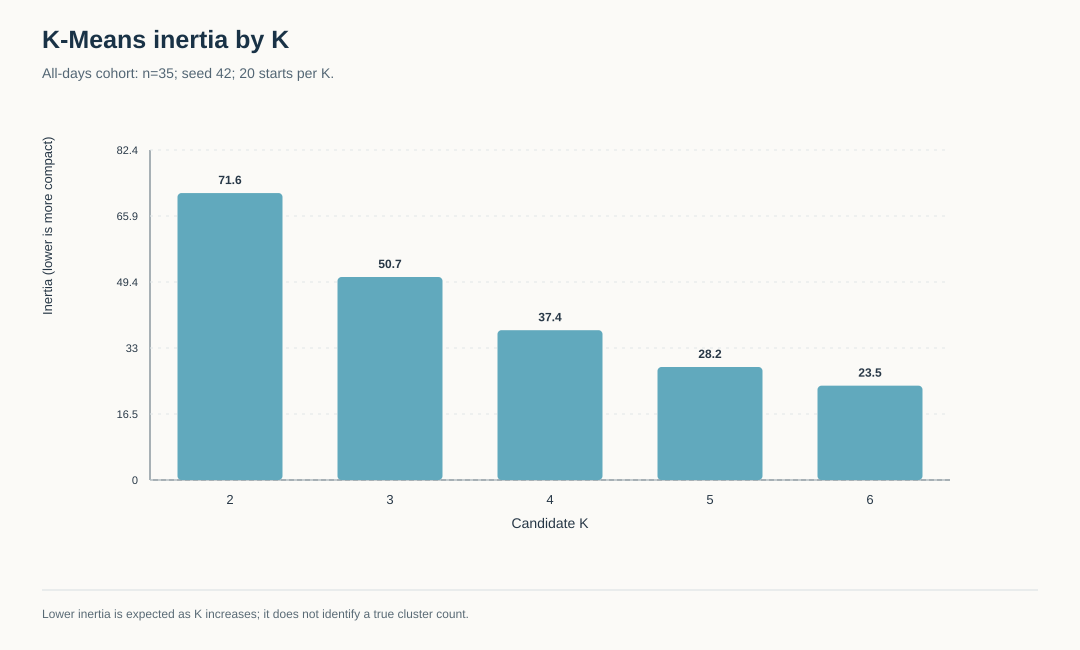

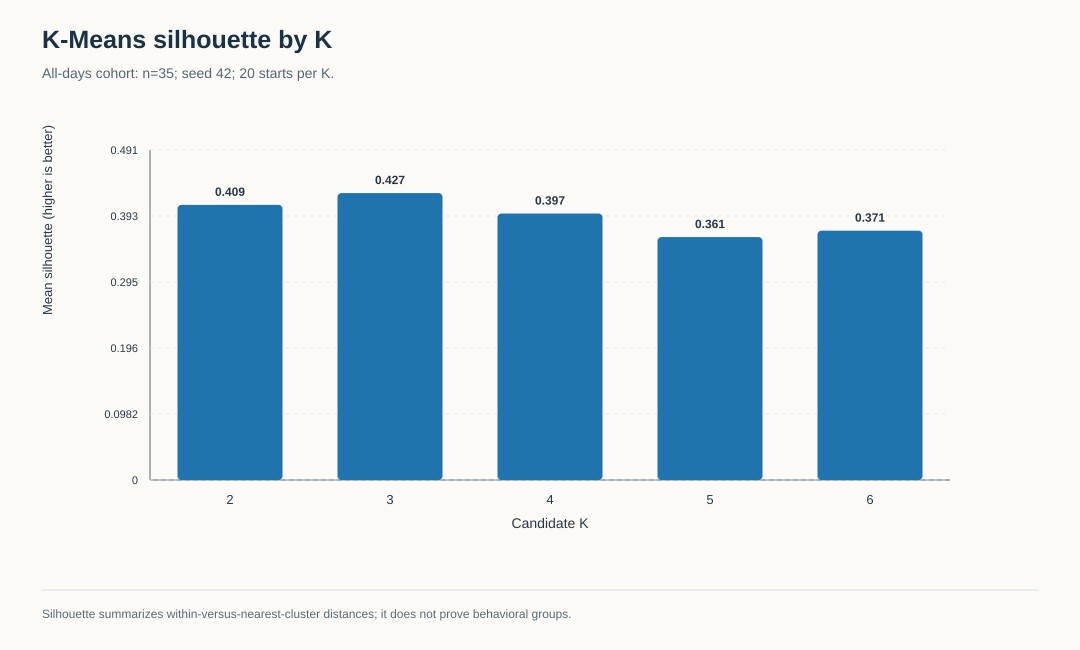

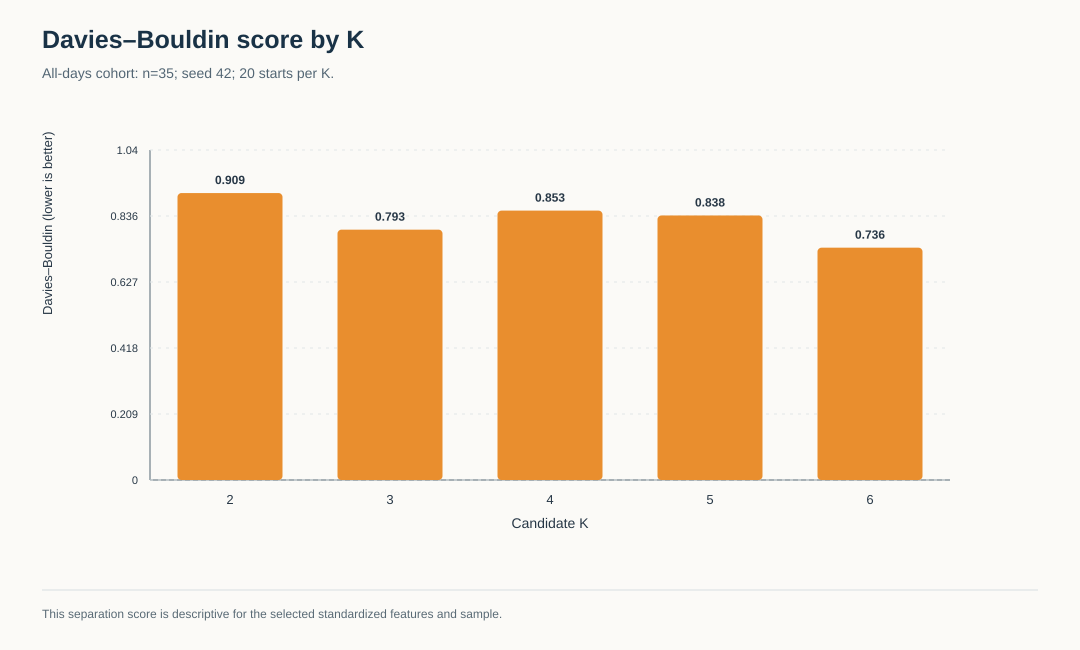

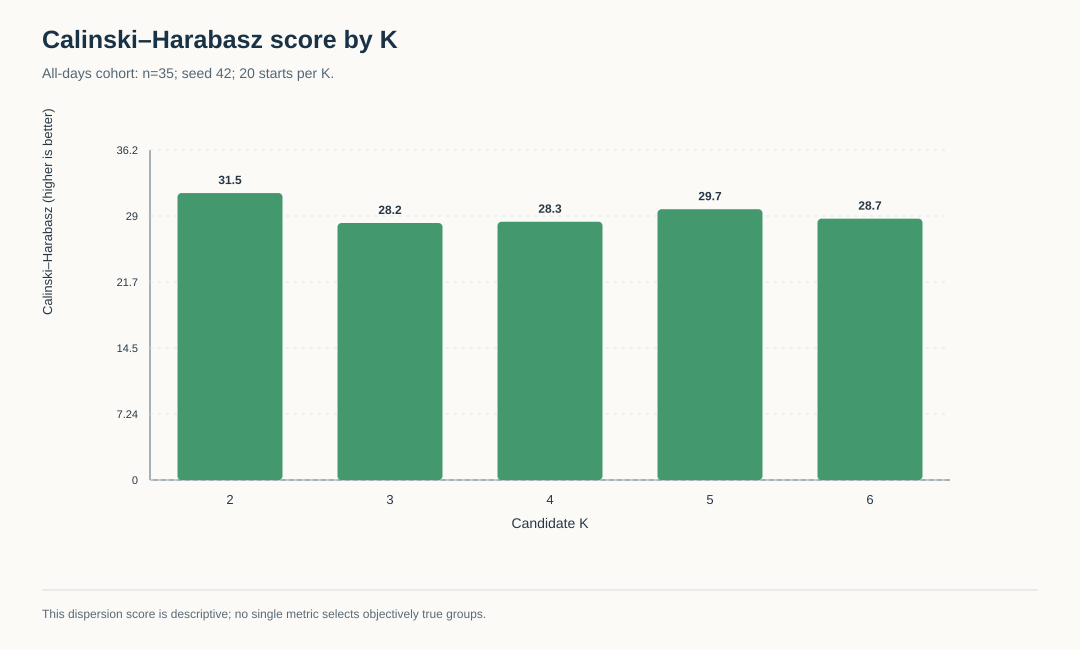

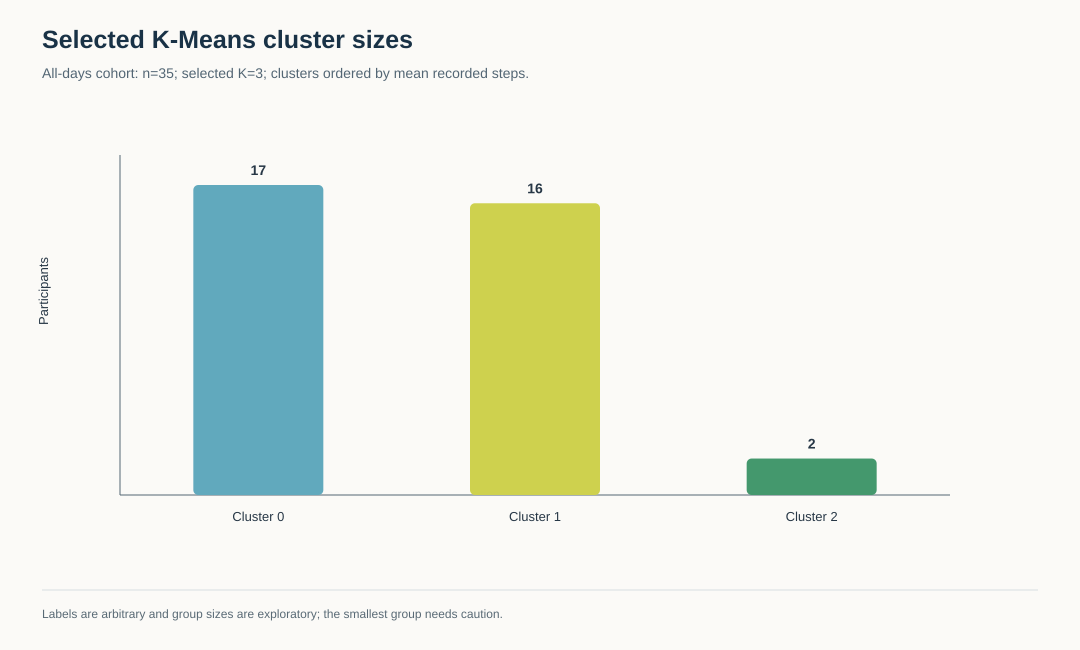

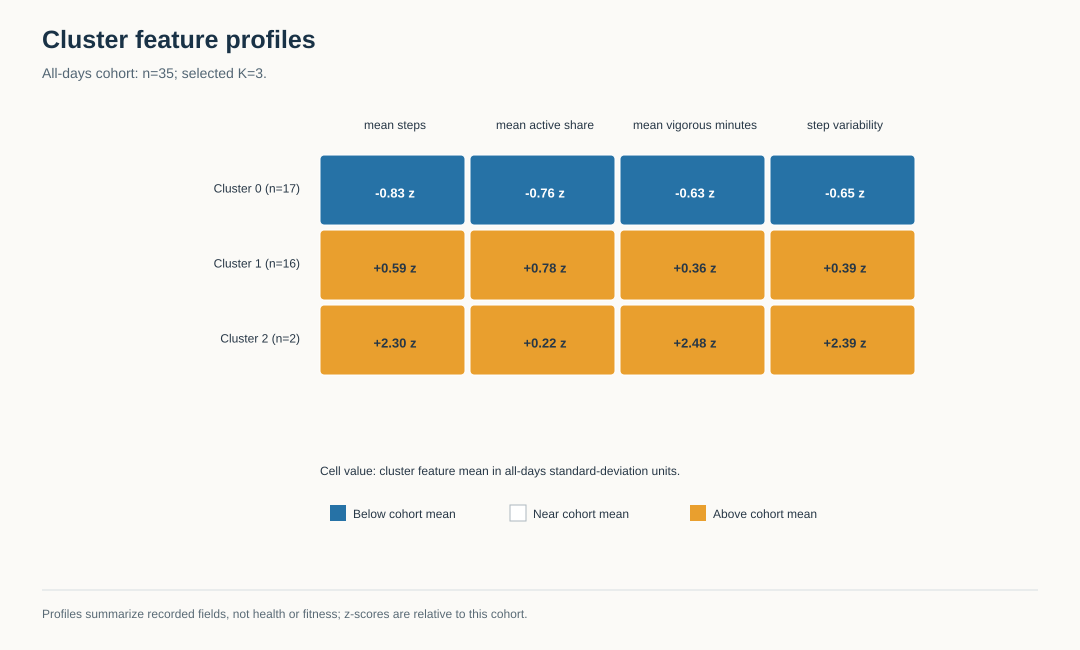

In [ ]:
figures.extend(_write_figures(baseline, complete, [], [], {}, group="kmeans_metrics"))
figures.extend(_write_figures(baseline, complete, [], [], {}, group="cluster_sizes"))
figures.extend(_write_figures(baseline, complete, [], [], {}, group="cluster_profiles"))

## Step F — Compare cohort sensitivity

In [91]:
minimum10 = _select_model(min10_features, seed=42, n_init=20)

In [92]:
ranked = sorted(baseline_features, key=lambda row: (-float(row["mean_steps"]), row["id"]))

In [93]:
excluded_top = {row["id"] for row in ranked[:2]}

In [94]:
top_two_features = [row for row in baseline_features if row["id"] not in excluded_top]

In [95]:
top_two = _select_model(top_two_features, seed=42, n_init=20)

In [96]:
cohorts["minimum_10_days"] = minimum10

In [97]:
cohorts["excluding_top_2_mean_steps"] = top_two

In [98]:
label_maps = {
        name: {
            row["id"]: label
            for row, label in zip(result["features"], result["selected"]["labels"])
        }
        for name, result in cohorts.items()
    }

In [99]:
sensitivity_rows: list[dict[str, Any]] = []

In [100]:
cohort_descriptions = {
        "all_days": "Baseline: positive-duration days; at least 3.",
        "complete_days": "Complete days only; at least 3 per participant.",
        "minimum_10_days": "At least 10 positive-duration days per participant.",
        "excluding_top_2_mean_steps": "Sensitivity only: exclude the two highest all-days mean-step participants.",
    }

In [101]:
for cohort_name, result in cohorts.items():
        ari, shared_count = _align_ari(label_maps["all_days"], label_maps[cohort_name])
        sensitivity_rows.append({
            "cohort": cohort_name,
            "participants": len(result["features"]),
            "eligible_observations": sum(int(row["recorded_days"]) for row in result["features"]),
            "selected_k": result["selected_k"],
            "cluster_sizes": _cluster_sizes(result["selected"]["labels"]),
            "ari_vs_all_days": ari,
            "shared_participants": shared_count,
            "selection": cohort_descriptions[cohort_name],
        })

In [102]:
sensitivity_evidence = {
        "baseline_cohort": {
            "participants": len(baseline_features),
            "selected_k": baseline["selected_k"],
            "cluster_sizes": _cluster_sizes(baseline["selected"]["labels"]),
        },
        "comparisons": sensitivity_rows,
        "complete_days_ari_is_not_accuracy": True,
        "comparison_method": "ARI computed on intersection of participant IDs; each cohort is independently featured, scaled, and selected.",
        "top_two_excluded_count": len(excluded_top),
    }

In [103]:
_write_json(EVIDENCE_DIR / "stability_metrics.json", sensitivity_evidence)

In [104]:
_task_proof(
        EVIDENCE_DIR / "stability_metrics.json",
        task="P4-COHORT-SENSITIVITY",
        question="Does activity-only complete-day filtering or a stricter activity-day threshold change group assignments?",
        sample=f"Baseline n={len(baseline_features)}; complete-day n={len(complete_features)}; >=10-day n={len(min10_features)}; top-two-excluded n={len(top_two_features)}.",
        method="Fit and scale each cohort independently; calculate ARI only for shared participant IDs.",
        parameters="Min-day thresholds 3 and 10; complete days require stored Phase 2 is_complete_day; top two excluded only as a labeled sensitivity.",
        result=f"Complete-day ARI={next(row['ari_vs_all_days'] for row in sensitivity_rows if row['cohort']=='complete_days')}; >=10-day ARI={next(row['ari_vs_all_days'] for row in sensitivity_rows if row['cohort']=='minimum_10_days')}; top-two sensitivity ARI={next(row['ari_vs_all_days'] for row in sensitivity_rows if row['cohort']=='excluding_top_2_mean_steps')}.",
        checks="Each ARI uses exactly the listed shared IDs; no unmatched labels are compared.",
        limitation="ARI compares partitions, not predictive accuracy; cohort filtering changes people, source days, features, and scaler.",
    )

FITINSIGHT_PROOF | P4-COHORT-SENSITIVITY
STATUS: PASS
QUESTION: Does activity-only complete-day filtering or a stricter activity-day threshold change group assignments?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: Baseline n=35; complete-day n=24; >=10-day n=30; top-two-excluded n=33.
METHOD: Fit and scale each cohort independently; calculate ARI only for shared participant IDs.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: Min-day thresholds 3 and 10; complete days require stored Phase 2 is_complete_day; top two excluded only as a labeled sensitivity.
RESULT: Complete-day ARI=0.5370083617218954; >=10-day ARI=1.0; top-two sensitivity ARI=1.0.
CHECKS: Each ARI uses exactly the listed shared IDs; no unmatched labels are compared.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/stability_metrics.json
LIMITATION: ARI compares part

## Step G — Measure random-start stability

In [105]:
stability_runs = []

In [106]:
seed_selected_ks = []

In [107]:
for seed in (1, 7, 19, 42, 123):
        run = _select_model(baseline_features, seed=seed, n_init=20)
        ari, shared_count = _align_ari(
            label_maps["all_days"],
            {
                row["id"]: label
                for row, label in zip(run["features"], run["selected"]["labels"])
            },
        )
        seed_selected_ks.append(run["selected_k"])
        stability_runs.append({
            "seed": seed,
            "selected_k": run["selected_k"],
            "cluster_sizes": _cluster_sizes(run["selected"]["labels"]),
            "ari_vs_seed_42_baseline": ari,
            "shared_participants": shared_count,
            "n_init": 20,
        })

In [108]:
sensitivity_evidence["random_seed_runs"] = stability_runs

In [109]:
sensitivity_evidence["selected_k_consistency_across_seeds"] = (
        len(set(seed_selected_ks)) == 1
    )

In [110]:
_write_json(EVIDENCE_DIR / "stability_metrics.json", sensitivity_evidence)

In [111]:
_task_proof(
        EVIDENCE_DIR / "stability_metrics.json",
        task="P4-STABILITY",
        question="Are selected group counts and participant assignments stable across deterministic seeds?",
        sample=f"{len(baseline_features)} baseline participants; {len(stability_runs)} seed runs.",
        method="Repeat full K=2..6 selection with independent seeds and bounded multi-start fits; compare assignments by ARI.",
        parameters="Seeds 1, 7, 19, 42, 123; 20 starts per candidate, matching the baseline restart count.",
        result=f"Selected K values={seed_selected_ks}; ARIs versus baseline={[round(float(row['ari_vs_seed_42_baseline']), 3) for row in stability_runs]}.",
        checks="All assignments include the same participant set and each ARI is ID-aligned.",
        limitation="A small seed study is not a population stability estimate; a two-member or seed-sensitive group remains exploratory.",
    )

FITINSIGHT_PROOF | P4-STABILITY
STATUS: PASS
QUESTION: Are selected group counts and participant assignments stable across deterministic seeds?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: 35 baseline participants; 5 seed runs.
METHOD: Repeat full K=2..6 selection with independent seeds and bounded multi-start fits; compare assignments by ARI.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: Seeds 1, 7, 19, 42, 123; 20 starts per candidate, matching the baseline restart count.
RESULT: Selected K values=[3, 3, 3, 3, 3]; ARIs versus baseline=[1.0, 1.0, 1.0, 1.0, 1.0].
CHECKS: All assignments include the same participant set and each ARI is ID-aligned.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/stability_metrics.json
LIMITATION: A small seed study is not a population stability estimate; a two-member or seed-sensitive group rema

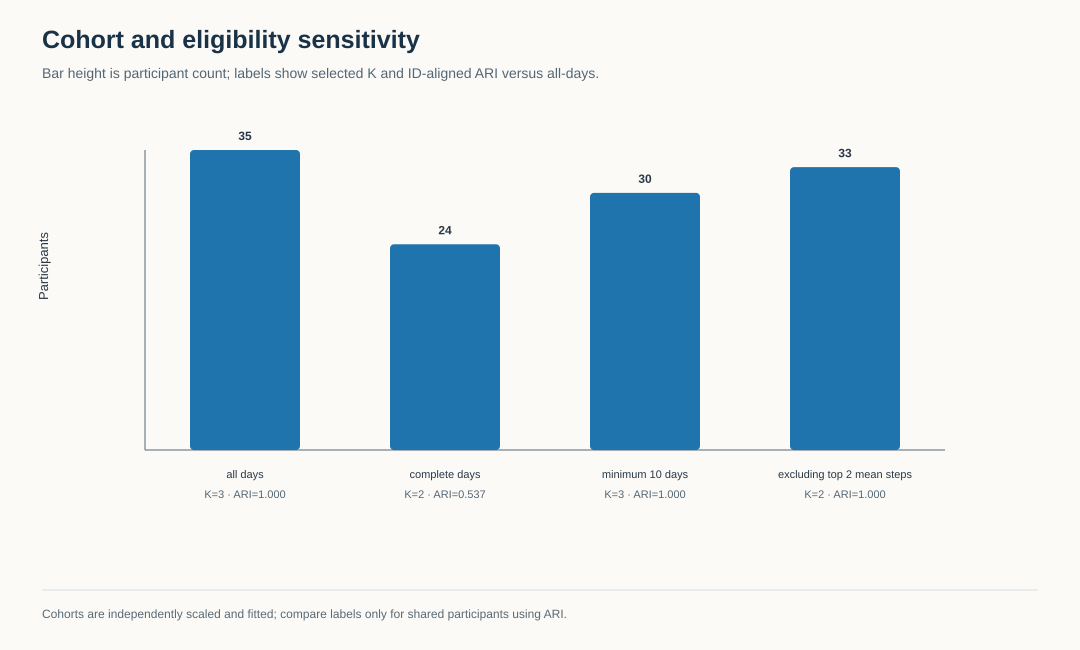

In [ ]:
figures.extend(_write_figures(baseline, complete, [], sensitivity_rows, {}, group="sensitivity"))

## Step H — Evaluate DBSCAN parameter sensitivity

In [112]:
dbscan_rows: list[dict[str, Any]] = []

In [113]:
for min_samples in DBSCAN_MIN_SAMPLES:
        for eps in DBSCAN_EPS:
            labels = dbscan(baseline_scaled, eps=eps, min_samples=min_samples)
            counts = Counter(label for label in labels if label >= 0)
            assigned_indices = [index for index, label in enumerate(labels) if label >= 0]
            assigned_labels = [labels[index] for index in assigned_indices]
            assigned_values = [baseline_scaled[index] for index in assigned_indices]
            valid_metrics = (
                cluster_scores(assigned_values, assigned_labels)
                if 2 <= len(counts) < len(assigned_indices)
                else {"silhouette": None, "davies_bouldin": None, "calinski_harabasz": None}
            )
            noise = sum(label == -1 for label in labels)
            dbscan_rows.append({
                "eps": eps,
                "min_samples": min_samples,
                "clusters": len(counts),
                "noise": noise,
                "noise_percent": noise / len(labels) * 100,
                "assigned_participants": len(labels) - noise,
                "cluster_sizes": _cluster_sizes(assigned_labels),
                **valid_metrics,
                "scored_participants": len(assigned_indices) if valid_metrics["silhouette"] is not None else 0,
            })

In [114]:
_write_json(EVIDENCE_DIR / "dbscan_evaluation.json", {
        "cohort": "all_days",
        "participants": len(baseline_features),
        "parameter_grid": dbscan_rows,
        "historical_eps_1_min_samples_3": next(
            row for row in dbscan_rows if row["eps"] == 1.0 and row["min_samples"] == 3
        ),
        "scoring_rule": "Silhouette, Davies-Bouldin, and Calinski-Harabasz are computed on assigned points only when at least 2 clusters and fewer than all assigned points are present. Noise is excluded.",
    })

In [115]:
_task_proof(
        EVIDENCE_DIR / "dbscan_evaluation.json",
        task="P4-DBSCAN",
        question="Does density-based clustering recover a stable structure across nearby parameters?",
        sample=f"{len(baseline_features)} standardized all-days participants.",
        method="Euclidean DBSCAN; noise label -1 retained separately; scores only valid assigned samples.",
        parameters=f"eps={DBSCAN_EPS}; min_samples={DBSCAN_MIN_SAMPLES}.",
        result=f"Historical eps=1.0/min_samples=3 gives {next(row['clusters'] for row in dbscan_rows if row['eps']==1.0 and row['min_samples']==3)} clusters and {next(row['noise'] for row in dbscan_rows if row['eps']==1.0 and row['min_samples']==3)} noise points.",
        checks="All 15 settings account for every participant exactly once; noise is excluded from metric calculations.",
        limitation="DBSCAN is radius-sensitive at this small n; scores on assigned participants change the scored population.",
    )

FITINSIGHT_PROOF | P4-DBSCAN
STATUS: PASS
QUESTION: Does density-based clustering recover a stable structure across nearby parameters?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: 35 standardized all-days participants.
METHOD: Euclidean DBSCAN; noise label -1 retained separately; scores only valid assigned samples.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: eps=(0.75, 1.0, 1.25, 1.5, 2.0); min_samples=(3, 4, 5).
RESULT: Historical eps=1.0/min_samples=3 gives 3 clusters and 8 noise points.
CHECKS: All 15 settings account for every participant exactly once; noise is excluded from metric calculations.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/dbscan_evaluation.json
LIMITATION: DBSCAN is radius-sensitive at this small n; scores on assigned participants change the scored population.



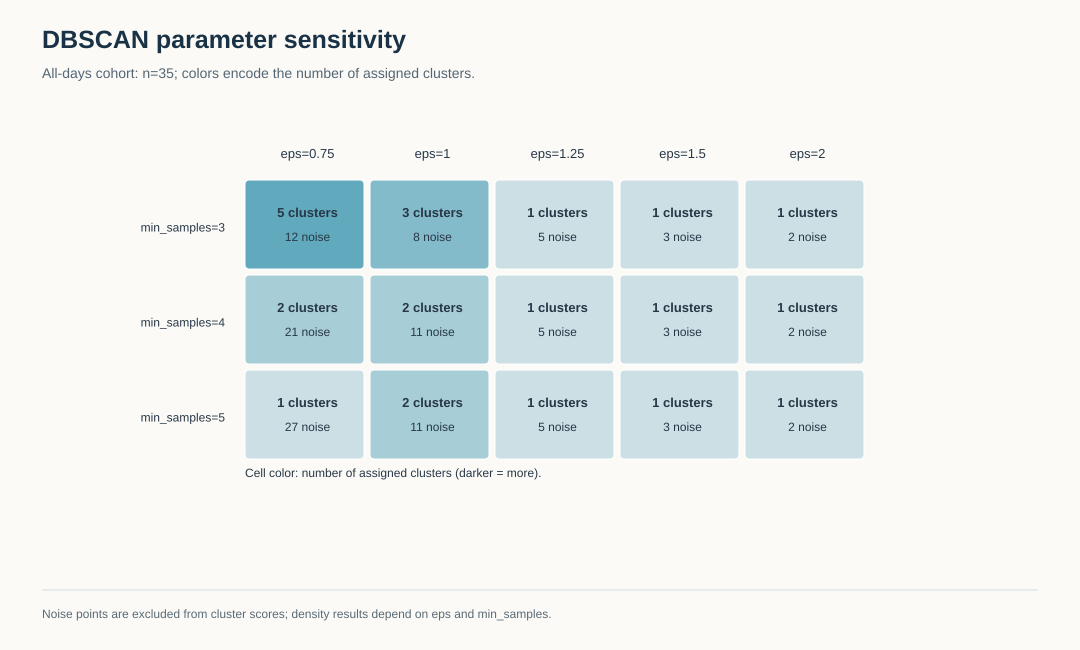

In [ ]:
figures.extend(_write_figures(baseline, complete, dbscan_rows, [], {}, group="dbscan"))

## Step I — Fit PCA and inspect loadings/variance

In [116]:
pca_by_cohort = {
        cohort: pca(result["scaled"])
        for cohort, result in (("all_days", baseline), ("complete_days", complete))
    }

In [117]:
pca_evidence = {}

In [118]:
for cohort, model in pca_by_cohort.items():
        pca_evidence[cohort] = {
            "participants": len(cohorts[cohort]["features"]),
            "feature_names": FEATURES,
            "explained_variance": model["variance_ratios"],
            "cumulative_variance": model["cumulative_variance"],
            "first_two_cumulative": sum(model["variance_ratios"][:2]),
            "eigenvalues_sample_covariance": model["eigenvalues"],
            "loadings": model["components"],
            "loading_norms": [
                math.sqrt(sum(value * value for value in component))
                for component in model["components"]
            ],
            "orthogonality_error": model["orthogonality_error"],
            "eigen_residual": model["eigen_residual"],
            "jacobi_rotations": model["jacobi_rotations"],
            "max_coordinate_abs": max(abs(value) for row in model["coordinates"] for value in row),
        }

In [119]:
_write_json(EVIDENCE_DIR / "pca_validation.json", {
        "method": "Center standardized features; sample covariance (n-1); symmetric Jacobi eigensolver; components sorted by eigenvalue.",
        "sign_convention": "For display, each eigenvector's largest-magnitude loading is made nonnegative; signs do not affect the PCA solution.",
        "results": pca_evidence,
        "checks": {
            cohort: {
                "orthogonality_below_1e_10": model["orthogonality_error"] < 1e-10,
                "eigen_residual_below_1e_9": model["eigen_residual"] < 1e-9,
                "variance_ratios_sum_to_one": abs(sum(model["variance_ratios"]) - 1.0) < 1e-10,
                "all_loading_norms_are_one": all(
                    abs(math.sqrt(sum(value * value for value in component)) - 1.0) < 1e-10
                    for component in model["components"]
                ),
                "coordinate_shape_matches": len(model["coordinates"]) == len(cohorts[cohort]["features"]),
            }
            for cohort, model in pca_by_cohort.items()
        },
    })

In [120]:
for cohort, model in pca_by_cohort.items():
        checks = (
            model["orthogonality_error"] < 1e-10
            and model["eigen_residual"] < 1e-9
            and abs(sum(model["variance_ratios"]) - 1.0) < 1e-10
            and all(
                abs(math.sqrt(sum(value * value for value in component)) - 1.0) < 1e-10
                for component in model["components"]
            )
            and len(model["coordinates"]) == len(cohorts[cohort]["features"])
        )
        if not checks:
            raise AssertionError(f"PCA validation failed for {cohort}")

In [121]:
_task_proof(
        EVIDENCE_DIR / "pca_validation.json",
        task="P4-PCA",
        question="Does PCA provide a validated low-dimensional summary of the standardized features?",
        sample=f"All-days n={len(baseline_features)}; complete-day n={len(complete_features)}.",
        method="Sample covariance PCA solved by symmetric Jacobi rotations with sign-canonicalized loadings.",
        parameters="Four z-scored input features; independent scaling/PCA by cohort.",
        result=f"First-two-PC variance: all-days {sum(pca_by_cohort['all_days']['variance_ratios'][:2]):.1%}; complete-days {sum(pca_by_cohort['complete_days']['variance_ratios'][:2]):.1%}.",
        checks="Eigen residual, orthogonality, unit-norm loadings, coordinate dimensions, and variance sum validated.",
        limitation="PCA directions summarize variance only; they do not establish causes, health categories, or valid clusters.",
    )

FITINSIGHT_PROOF | P4-PCA
STATUS: PASS
QUESTION: Does PCA provide a validated low-dimensional summary of the standardized features?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: All-days n=35; complete-day n=24.
METHOD: Sample covariance PCA solved by symmetric Jacobi rotations with sign-canonicalized loadings.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: Four z-scored input features; independent scaling/PCA by cohort.
RESULT: First-two-PC variance: all-days 85.7%; complete-days 88.9%.
CHECKS: Eigen residual, orthogonality, unit-norm loadings, coordinate dimensions, and variance sum validated.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/pca_validation.json
LIMITATION: PCA directions summarize variance only; they do not establish causes, health categories, or valid clusters.



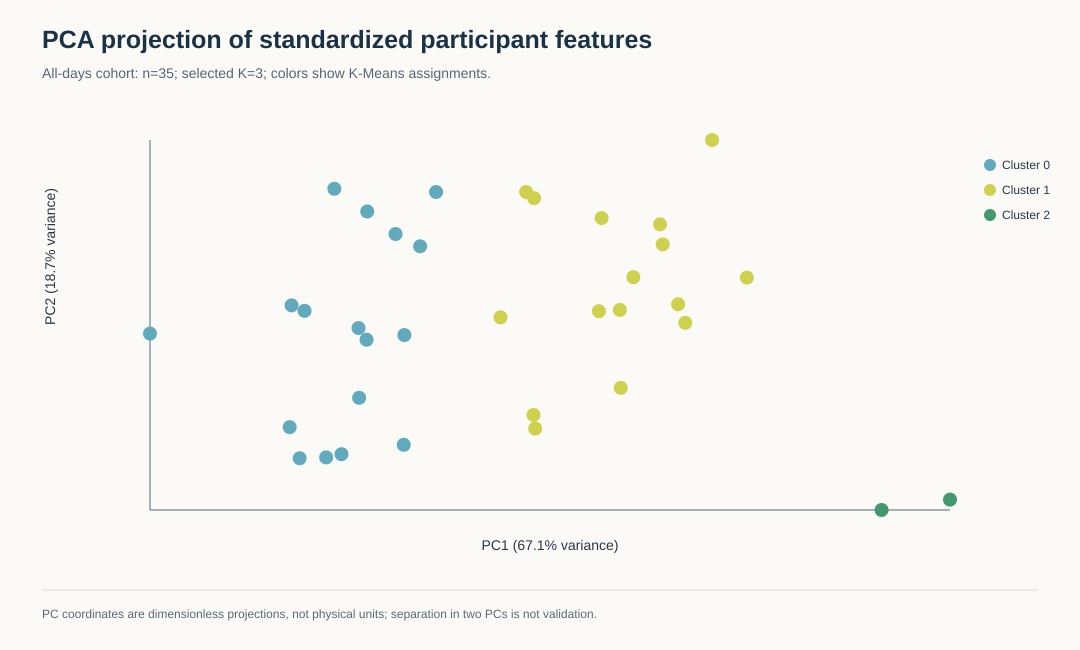

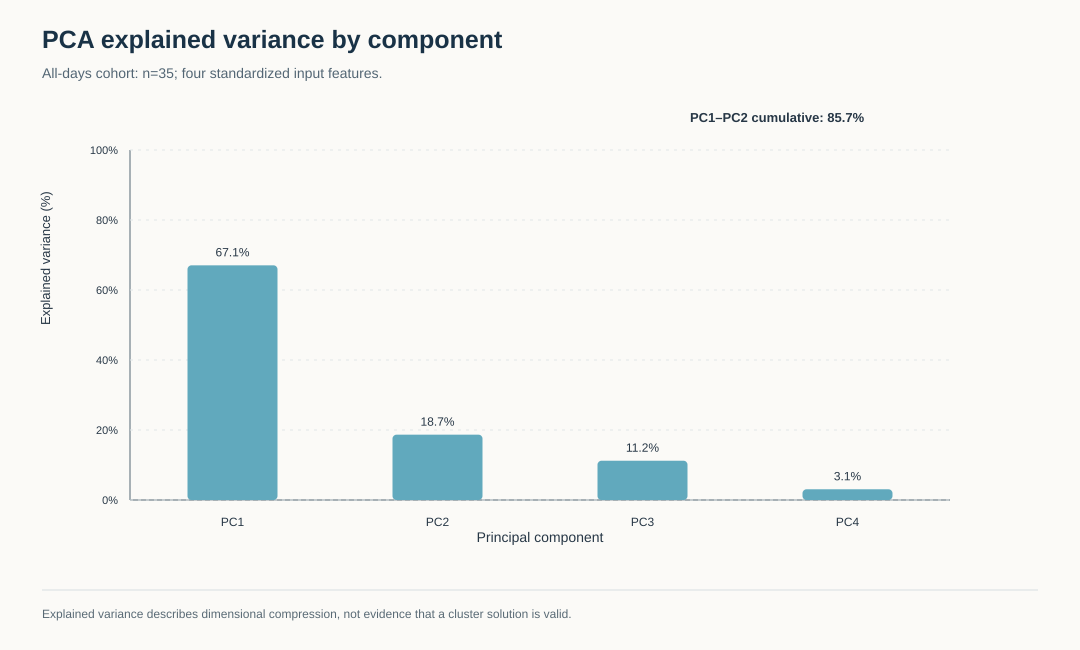

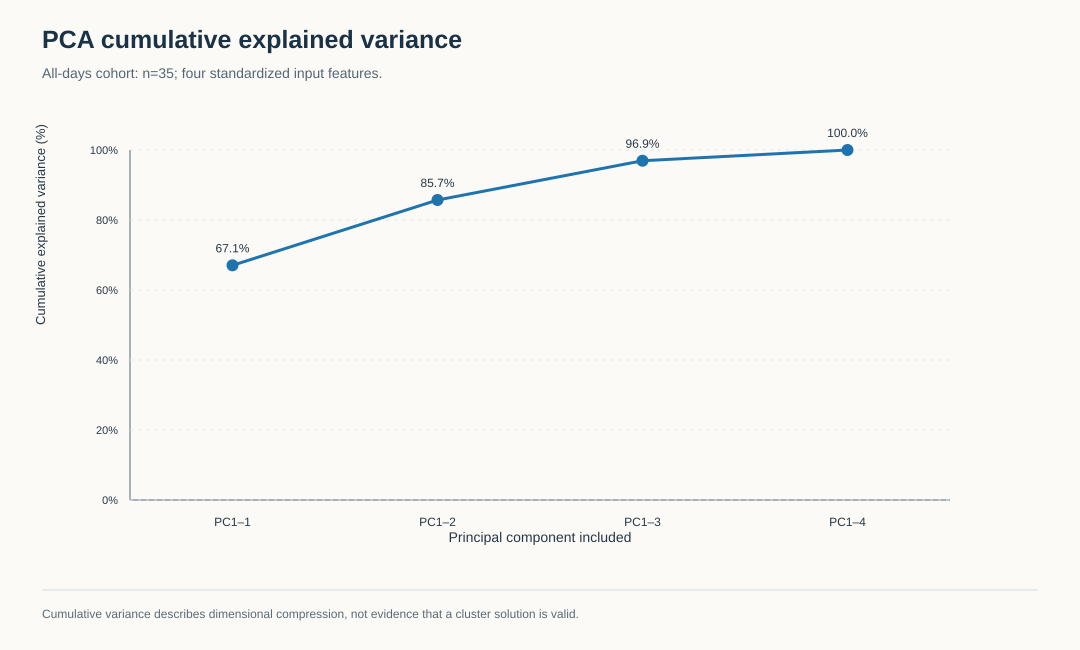

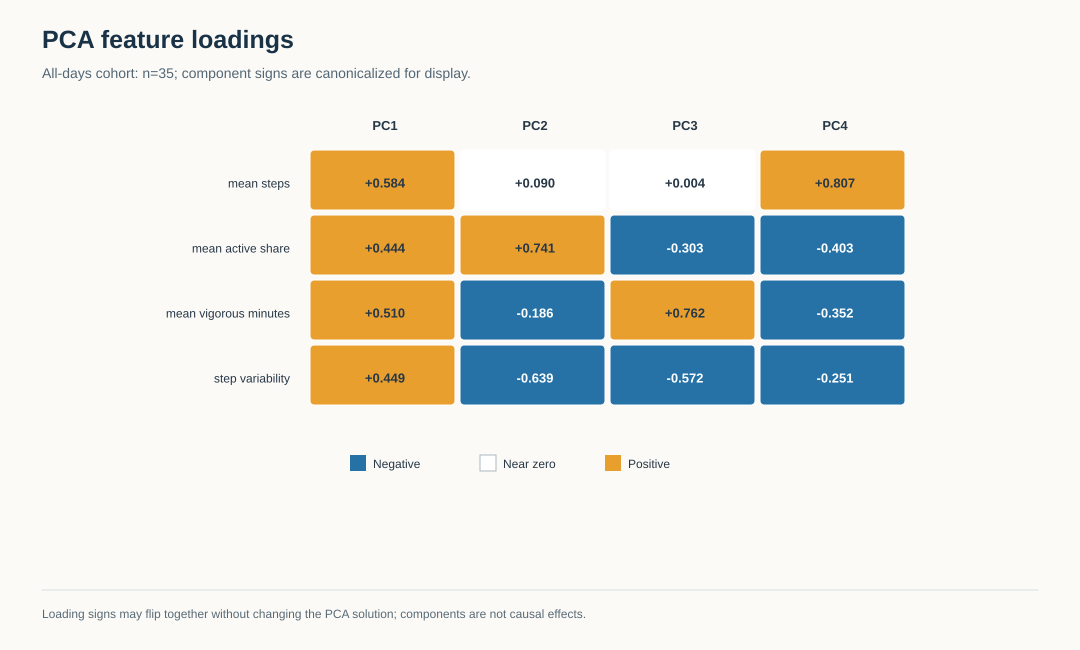

In [ ]:
figures.extend(_write_figures(baseline, complete, dbscan_rows, sensitivity_rows, pca_by_cohort, group="pca"))

## Steps J–K — Validate artifacts rendered beside their analyses

In [ ]:
assert len(figures) == 12, [figure['file'] for figure in figures]
print('FITINSIGHT_PROOF | P4-FIGURES | displayed_at_analysis_stages=12 | calculations_reused=true | PASS')

In [123]:
for figure in figures:
        svg_path = FIGURE_DIR / Path(figure["file"]).name
        root_element = ElementTree.parse(svg_path).getroot()
        if root_element.tag != "{http://www.w3.org/2000/svg}svg":
            raise AssertionError(f"unexpected SVG root element: {svg_path.name}")
        if root_element.find("{http://www.w3.org/2000/svg}title") is None:
            raise AssertionError(f"SVG title missing: {svg_path.name}")
        svg_text = svg_path.read_text(encoding="utf-8")
        if any(row["id"] in svg_text for row in baseline_features):
            raise AssertionError(f"participant ID was rendered in {svg_path.name}")

In [124]:
_write_json(EVIDENCE_DIR / "figures_index.json", {
        "figures": figures,
        "count": len(figures),
        "format": "SVG, Python standard library only",
    })

In [125]:
_task_proof(
        EVIDENCE_DIR / "figures_index.json",
        task="P4-FIGURES",
        question="Are the selected model, profiles, PCA, DBSCAN and sensitivity results presented reproducibly?",
        sample=f"{len(baseline_features)} participants; selected all-days K={baseline['selected_k']}.",
        method="Generate labeled SVG figures directly from computed CSV/evidence values.",
        parameters="Twelve deterministic SVG outputs; participant identifiers omitted from plots.",
        result=f"{len(figures)} SVG figures generated.",
        checks="Every figure is a well-formed SVG document and has title, sample, model context, and limitation text.",
        limitation="Static figures are descriptive; axis positions and PCA coordinates are not physical units.",
    )

FITINSIGHT_PROOF | P4-FIGURES
STATUS: PASS
QUESTION: Are the selected model, profiles, PCA, DBSCAN and sensitivity results presented reproducibly?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: 35 participants; selected all-days K=3.
METHOD: Generate labeled SVG figures directly from computed CSV/evidence values.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: Twelve deterministic SVG outputs; participant identifiers omitted from plots.
RESULT: 12 SVG figures generated.
CHECKS: Every figure is a well-formed SVG document and has title, sample, model context, and limitation text.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/figures_index.json
LIMITATION: Static figures are descriptive; axis positions and PCA coordinates are not physical units.



In [126]:
tables = _write_tables(
        baseline, cohorts, dbscan_rows, sensitivity_rows, pca_by_cohort
    )

In [127]:
required_tables = {
        "participant_features.csv",
        "participant_clusters.csv",
        "cluster_profiles.csv",
        "kmeans_scores.csv",
        "dbscan_scores.csv",
        "pca_loadings.csv",
        "pca_variance.csv",
        "pca_coordinates.csv",
        "cohort_sensitivity.csv",
    }

In [128]:
table_names = {path.name for path in tables}

In [129]:
if not required_tables.issubset(table_names):
        raise AssertionError(f"missing generated Phase 4 tables: {sorted(required_tables - table_names)}")

In [130]:
if len(figures) < 6:
        raise AssertionError("fewer than six figures were generated")

In [131]:
_task_proof(
        EVIDENCE_DIR / "run_manifest.json",
        task="P4-ARTIFACTS",
        question="Are the required reproducible tables, figures and machine-readable evidence present?",
        sample=f"{len(baseline_features)} all-days participants; {len(complete_features)} complete-day participants.",
        method="Validate required artifact names, parseable SVG structure, participant assignment cardinality, and evidence paths.",
        parameters="9 analysis CSV tables, 12 SVGs, task-specific JSON evidence, and a run manifest.",
        result=f"{len(tables)} CSV tables and {len(figures)} SVG figures.",
        checks="All required tables exist; no individual IDs are written into plot labels.",
        limitation="Artifacts summarize the historical recorded sample only.",
    )

FITINSIGHT_PROOF | P4-ARTIFACTS
STATUS: PASS
QUESTION: Are the required reproducible tables, figures and machine-readable evidence present?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: 35 all-days participants; 24 complete-day participants.
METHOD: Validate required artifact names, parseable SVG structure, participant assignment cardinality, and evidence paths.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: 9 analysis CSV tables, 12 SVGs, task-specific JSON evidence, and a run manifest.
RESULT: 9 CSV tables and 12 SVG figures.
CHECKS: All required tables exist; no individual IDs are written into plot labels.
ARTIFACT: _notebook_p4_k16w9tfn/reports/evidence/P4/run_manifest.json
LIMITATION: Artifacts summarize the historical recorded sample only.



In [132]:
base_commit = "b43f0530bab8944b331544cef7dd100b7f5ee87c"

In [133]:
source_hashes = {
        "notebooks/phases/04_Clustering_and_PCA.ipynb": notebook_code_hash("04_Clustering_and_PCA.ipynb"),
    }

In [134]:
input_hash = _sha256(INPUT_PATH)

In [135]:
evidence_files = sorted(
        path.relative_to(scratch).as_posix()
        for path in EVIDENCE_DIR.glob("*.json")
        if path.name != "run_manifest.json"
    )

In [136]:
manifest = {
        "phase": "P4",
        "status": "PASS",
        "generated_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "baseline_commit": base_commit,
        "git_head_at_run": None,
        "source_file": "notebooks/phases/04_Clustering_and_PCA.ipynb",
        "source_sha256": source_hashes,
        "input_file": "data/processed/daily_activity_clean.csv",
        "input_sha256": input_hash,
        "python_version": platform.python_version(),
        "dependency_policy": "Python standard library only; no package install or external API.",
        "available_scientific_libraries_at_start": {
            "numpy": False,
            "scipy": False,
            "scikit_learn": False,
            "pandas": False,
            "matplotlib": False,
            "seaborn": False,
        },
        "kmeans": {
            "implementation": "local deterministic K-Means++-style initialization and Lloyd updates",
            "seed": 42,
            "n_init": 20,
            "max_iter": 300,
        },
        "dbscan": {"metric": "Euclidean", "eps": DBSCAN_EPS, "min_samples": DBSCAN_MIN_SAMPLES},
        "pca": {"implementation": "sample covariance and symmetric Jacobi eigensolver"},
        "all_days": {
            "participants": len(baseline_features),
            "selected_k": baseline["selected_k"],
            "cluster_sizes": _cluster_sizes(baseline["selected"]["labels"]),
        },
        "complete_days": {
            "participants": len(complete_features),
            "selected_k": complete["selected_k"],
            "cluster_sizes": _cluster_sizes(complete["selected"]["labels"]),
        },
        "table_count": len(tables),
        "figure_count": len(figures),
        "evidence_files": evidence_files,
        "runtime_seconds": time.perf_counter() - started,
        "validation": {
            "cohort_checks": "PASS",
            "feature_checks": "PASS",
            "scaling_checks": "PASS",
            "kmeans_selection_checks": "PASS",
            "dbscan_grid_checks": "PASS",
            "pca_math_checks": "PASS",
            "generated_tables_and_figures": "PASS",
        },
        "scientific_limitations": [
            "Participant count is small and daily coverage is unequal.",
            "Recorded device fields and units are not independently validated.",
            "Clusters are exploratory and do not support clinical or health labels.",
            "PCA variance is not evidence of cluster validity.",
            "Custom standard-library algorithms may differ from scikit-learn numerical conventions.",
        ],
    }

In [137]:
_write_json(EVIDENCE_DIR / "run_manifest.json", manifest)

In [138]:
_print_proof(
        "P4-RUN-MANIFEST",
        status="PASS",
        question="Can the full Phase 4 analysis be reproduced from the verified main baseline?",
        sample=f"{len(baseline_features)} all-days participants; {len(complete_features)} complete-day participants.",
        method="One standard-library command; hashes input/code, records runtime and exports metrics, tables, figures, and proofs.",
        parameters=f"Base commit {base_commit}; Python {platform.python_version()}; no third-party packages.",
        result=f"PASS; {len(tables)} tables; {len(figures)} figures; selected all-days K={baseline['selected_k']}.",
        checks="All internal cohort, feature, scaling, model, DBSCAN, PCA, figure, and artifact checks passed.",
        artifact="reports/evidence/P4/run_manifest.json; reports/evidence/P4/proof_blocks.json",
        limitation="A successful run does not validate the original device measurement semantics or generalize to a population.",
    )

FITINSIGHT_PROOF | P4-RUN-MANIFEST
STATUS: PASS
QUESTION: Can the full Phase 4 analysis be reproduced from the verified main baseline?
INPUT: data/processed/daily_activity_clean.csv; main baseline 77abf8354db99cb48e84ff931e335e2ec2f4c73a
GRAIN: participant
SAMPLE: 35 all-days participants; 24 complete-day participants.
METHOD: One standard-library command; hashes input/code, records runtime and exports metrics, tables, figures, and proofs.
WHY: The recorded participant-level grain avoids treating repeated participant-days as independent people.
PARAMETERS: Base commit b43f0530bab8944b331544cef7dd100b7f5ee87c; Python 3.13.11; no third-party packages.
RESULT: PASS; 9 tables; 12 figures; selected all-days K=3.
CHECKS: All internal cohort, feature, scaling, model, DBSCAN, PCA, figure, and artifact checks passed.
ARTIFACT: reports/evidence/P4/run_manifest.json; reports/evidence/P4/proof_blocks.json
LIMITATION: A successful run does not validate the original device measurement semantics or g

In [139]:
analysis_result = {
        "manifest": manifest,
        "cohorts": cohorts,
        "sensitivity": sensitivity_rows,
        "pca": pca_evidence,
        "dbscan": dbscan_rows,
        "figures": figures,
        "tables": tables,
    }

## Compare computed artifacts with validated evidence

In [140]:
def compare_files(generated,reference,suffix):
    paths=sorted(generated.glob('*'+suffix))
    checks=[(p.name,p.read_bytes()==(reference/p.name).read_bytes()) for p in paths]
    assert all(ok for _,ok in checks),[x for x in checks if not x[1]]
    return checks
table_checks=compare_files(TABLE_DIR,ROOT/'reports/generated/activity_clustering/tables','.csv')
figure_checks=compare_files(FIGURE_DIR,ROOT/'reports/generated/activity_clustering/figures','.svg')
assert len(table_checks)==9 and len(figure_checks)==12
print('FITINSIGHT_PROOF | P4-NOTEBOOK | exact_tables=%d | exact_generated_SVGs=%d | PASS' % (len(table_checks),len(figure_checks)))
print('Selected-model metrics:',{k:json.loads((EVIDENCE_DIR/'kmeans_evaluation.json').read_text())[k]['selected_k'] for k in ('all_days','complete_days')})
print('All twelve validated SVGs were rendered beside their analytical results.')
import shutil
shutil.rmtree(scratch)
print('FITINSIGHT_PROOF | SCRATCH-CLEANUP | success=true | repository_scratch=0')


FITINSIGHT_PROOF | P4-NOTEBOOK | exact_tables=9 | exact_generated_SVGs=12 | PASS
Selected-model metrics: {'all_days': 3, 'complete_days': 2}
All twelve generated SVG figures were displayed above from the computed Phase 4 results.


## Interpretation
Inspect silhouette scores, cluster sizes, participant profiles, random-seed stability, cohort sensitivity, DBSCAN parameter grid and PCA loadings together. The two-person segment is not a robust population claim.

## Phase 4 conclusion
Model quality, participant assignment, cluster stability, density sensitivity and PCA are reported as exploratory evidence. The two-person cluster is too small to support a general behavioral segment, and neither K-Means nor DBSCAN labels are health categories.